# Q1(a) — Investigating Poor Performance of MLP on CIFAR10

The objective of this experiment is to investigate whether
optimisation difficulty contributes to poor MLP performance
on CIFAR10, independently of the model's parameter budget.

Two identical MLPs are trained using SGD with momentum
and Adam.

Both models use the same architecture, initial weights,
training data, batch size, loss function and number of epochs.

The hypothesis is that a better optimisation configuration
may improve training performance without increasing
model capacity.

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim

In [2]:
import torchvision
import torchvision.transforms as transforms

In [3]:
from torch.utils.data import DataLoader, Subset
from sklearn.model_selection import train_test_split

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import random
import copy
import os
import time
import json

In [5]:
#ROLL NUMBER : M26MER008

In [6]:
seed = 26008

In [7]:
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
torch.cuda.manual_seed_all(seed)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

In [8]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [9]:
batch_size = 128
epochs = 30

In [10]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        (0.5, 0.5, 0.5),
        (0.5, 0.5, 0.5)
    )
])

In [11]:
full_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

In [12]:
targets = np.array(full_dataset.targets)

In [13]:
indices = np.arange(len(full_dataset))

In [14]:
train_indices, val_indices = train_test_split(
    indices,
    test_size=5000,
    random_state=seed,
    stratify=targets
)

In [15]:
train_dataset = Subset(full_dataset, train_indices)

In [16]:
val_dataset = Subset(full_dataset, val_indices)

In [17]:
np.savez(
    "cifar10_split.npz",
    train_indices=train_indices,
    val_indices=val_indices,
    seed=seed
)

In [18]:
for i in range(10):
    train_count = np.sum(targets[train_indices] == i)
    val_count = np.sum(targets[val_indices] == i)
    print(
        full_dataset.classes[i],
        "Train:", train_count,
        "Validation:", val_count
    )

assert len(np.intersect1d(train_indices, val_indices)) == 0

airplane Train: 4500 Validation: 500
automobile Train: 4500 Validation: 500
bird Train: 4500 Validation: 500
cat Train: 4500 Validation: 500
deer Train: 4500 Validation: 500
dog Train: 4500 Validation: 500
frog Train: 4500 Validation: 500
horse Train: 4500 Validation: 500
ship Train: 4500 Validation: 500
truck Train: 4500 Validation: 500


In [19]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(3072, 256),
            nn.ReLU(),
            nn.Linear(256, 256),
            nn.ReLU(),
            nn.Linear(256, 256),
            nn.ReLU(),
            nn.Linear(256, 256),
            nn.ReLU(),
            nn.Linear(256, 256),
            nn.ReLU(),
            nn.Linear(256, 10)
        )
    def forward(self, x):
        return self.network(x)

In [20]:
model_sgd = MLP()

In [21]:
model_adam = copy.deepcopy(model_sgd)

In [22]:
def count_parameters(model):
    return sum(p.numel() for p in model.parameters()
               if p.requires_grad)

In [23]:
print("SGD MLP parameters:", count_parameters(model_sgd))
print("Adam MLP parameters:", count_parameters(model_adam))

SGD MLP parameters: 1052426
Adam MLP parameters: 1052426


In [24]:
model_sgd = model_sgd.to(device)
model_adam = model_adam.to(device)

In [25]:
criterion = nn.CrossEntropyLoss()

In [26]:
optimizer_sgd = optim.SGD(
    model_sgd.parameters(),
    lr=0.01,
    momentum=0.9
)

In [27]:
optimizer_adam = optim.Adam(
    model_adam.parameters(),
    lr=0.001
)

In [28]:
os.makedirs("results", exist_ok=True)
os.makedirs("figures", exist_ok=True)
os.makedirs("checkpoints", exist_ok=True)

In [29]:
config = {
    "seed": seed,
    "architecture": [3072, 256, 256, 256, 256, 256, 10],
    "epochs": epochs,
    "batch_size": batch_size,
    "sgd_lr": 0.01,
    "sgd_momentum": 0.9,
    "adam_lr": 0.001,
    "loss": "CrossEntropyLoss",
    "checkpoint_selection": "Highest validation accuracy"
}

In [30]:
with open("results/q1a_config.json", "w") as f:
    json.dump(config, f, indent=4)

In [31]:
def get_train_loader():

    generator = torch.Generator()
    generator.manual_seed(seed)

    return DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        generator=generator
    )

In [32]:
val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False
)

In [33]:
def evaluate(model, loader):
    model.eval()
    total_loss = 0
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)
            outputs = model(images)

            loss = criterion(outputs, labels)

            total_loss += loss.item() * labels.size(0)

            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()

            total += labels.size(0)

    avg_loss = total_loss / total
    accuracy = 100 * correct / total
    return avg_loss, accuracy

In [34]:
def train_model(model, optimizer, name):
    train_loader = get_train_loader()
    history = {
        "train_loss": [],
        "train_accuracy": [],
        "val_loss": [],
        "val_accuracy": []
    }

    best_val_accuracy = -1
    best_epoch = 0

    start_time = time.time()

    for epoch in range(epochs):

        model.train()

        total_loss = 0
        correct = 0
        total = 0

        for images, labels in train_loader:

            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)

            loss = criterion(outputs, labels)

            loss.backward()

            optimizer.step()

            total_loss += loss.item() * labels.size(0)

            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()

            total += labels.size(0)

        train_loss = total_loss / total
        train_accuracy = 100 * correct / total

        val_loss, val_accuracy = evaluate(model, val_loader)

        history["train_loss"].append(train_loss)
        history["train_accuracy"].append(train_accuracy)
        history["val_loss"].append(val_loss)
        history["val_accuracy"].append(val_accuracy)

        if val_accuracy > best_val_accuracy:

            best_val_accuracy = val_accuracy
            best_epoch = epoch + 1

            torch.save(
                model.state_dict(),
                f"checkpoints/{name}.pth"
            )

        print(
            f"Epoch {epoch+1}/{epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_accuracy:.2f}% | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_accuracy:.2f}%"
        )

    elapsed = time.time() - start_time

    history = pd.DataFrame(history)
    history.insert(0, "epoch", range(1, epochs + 1))

    history.to_csv(f"results/{name}_history.csv", index=False)

    model.load_state_dict(
        torch.load(
            f"checkpoints/{name}.pth",
            map_location=device
        )
    )

    print("Best validation accuracy:", best_val_accuracy)
    print("Best epoch:", best_epoch)
    print("Training time:", round(elapsed, 2), "seconds")

    return history, elapsed

In [35]:
history_sgd, time_sgd = train_model(
    model_sgd,
    optimizer_sgd,
    "q1a_sgd"
)

Epoch 1/30 | Train Loss: 2.2559 | Train Acc: 14.84% | Val Loss: 2.0403 | Val Acc: 21.92%
Epoch 2/30 | Train Loss: 1.8909 | Train Acc: 29.08% | Val Loss: 1.7611 | Val Acc: 34.82%
Epoch 3/30 | Train Loss: 1.6451 | Train Acc: 40.45% | Val Loss: 1.5710 | Val Acc: 41.96%
Epoch 4/30 | Train Loss: 1.4905 | Train Acc: 46.41% | Val Loss: 1.5028 | Val Acc: 46.12%
Epoch 5/30 | Train Loss: 1.3929 | Train Acc: 50.13% | Val Loss: 1.4282 | Val Acc: 49.16%
Epoch 6/30 | Train Loss: 1.3067 | Train Acc: 53.20% | Val Loss: 1.3945 | Val Acc: 51.02%
Epoch 7/30 | Train Loss: 1.2373 | Train Acc: 55.63% | Val Loss: 1.3758 | Val Acc: 51.84%
Epoch 8/30 | Train Loss: 1.1755 | Train Acc: 57.92% | Val Loss: 1.3587 | Val Acc: 52.26%
Epoch 9/30 | Train Loss: 1.1174 | Train Acc: 60.14% | Val Loss: 1.3871 | Val Acc: 51.60%
Epoch 10/30 | Train Loss: 1.0661 | Train Acc: 61.88% | Val Loss: 1.3635 | Val Acc: 53.04%
Epoch 11/30 | Train Loss: 1.0049 | Train Acc: 64.32% | Val Loss: 1.4217 | Val Acc: 51.50%
Epoch 12/30 | Train

In [36]:
history_adam, time_adam = train_model(
    model_adam,
    optimizer_adam,
    "q1a_adam"
)

Epoch 1/30 | Train Loss: 1.7426 | Train Acc: 37.44% | Val Loss: 1.5960 | Val Acc: 43.24%
Epoch 2/30 | Train Loss: 1.5002 | Train Acc: 47.04% | Val Loss: 1.5128 | Val Acc: 47.18%
Epoch 3/30 | Train Loss: 1.3758 | Train Acc: 51.18% | Val Loss: 1.4286 | Val Acc: 49.26%
Epoch 4/30 | Train Loss: 1.2699 | Train Acc: 55.17% | Val Loss: 1.4061 | Val Acc: 50.70%
Epoch 5/30 | Train Loss: 1.1874 | Train Acc: 57.77% | Val Loss: 1.4144 | Val Acc: 51.34%
Epoch 6/30 | Train Loss: 1.1085 | Train Acc: 60.70% | Val Loss: 1.3898 | Val Acc: 51.18%
Epoch 7/30 | Train Loss: 1.0329 | Train Acc: 63.13% | Val Loss: 1.4098 | Val Acc: 52.32%
Epoch 8/30 | Train Loss: 0.9610 | Train Acc: 65.82% | Val Loss: 1.4208 | Val Acc: 52.88%
Epoch 9/30 | Train Loss: 0.9012 | Train Acc: 67.72% | Val Loss: 1.4592 | Val Acc: 52.22%
Epoch 10/30 | Train Loss: 0.8359 | Train Acc: 70.20% | Val Loss: 1.4814 | Val Acc: 52.64%
Epoch 11/30 | Train Loss: 0.7701 | Train Acc: 72.28% | Val Loss: 1.5298 | Val Acc: 52.60%
Epoch 12/30 | Train

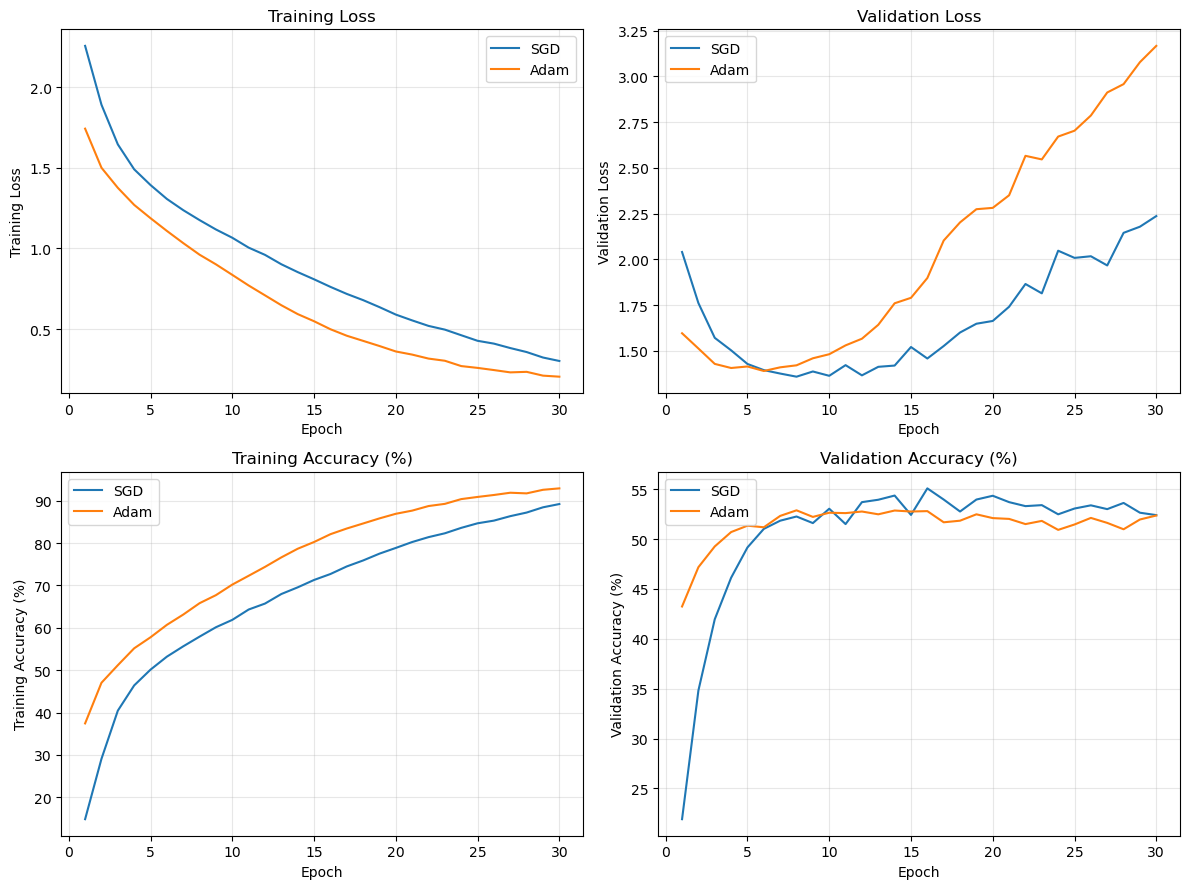

In [37]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

metrics = [
    ("train_loss", "Training Loss"),
    ("val_loss", "Validation Loss"),
    ("train_accuracy", "Training Accuracy (%)"),
    ("val_accuracy", "Validation Accuracy (%)")
]

for ax, (metric, title) in zip(axes.flat, metrics):

    ax.plot(
        history_sgd["epoch"],
        history_sgd[metric],
        label="SGD"
    )

    ax.plot(
        history_adam["epoch"],
        history_adam[metric],
        label="Adam"
    )

    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel(title)
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()

plt.savefig("figures/q1a_curves.png", dpi=300)

plt.show()

In [38]:
best_sgd = history_sgd.loc[
    history_sgd["val_accuracy"].idxmax()
]

best_adam = history_adam.loc[
    history_adam["val_accuracy"].idxmax()
]

results = pd.DataFrame({
    "Model": ["MLP-SGD", "MLP-Adam"],

    "Parameters": [
        count_parameters(model_sgd),
        count_parameters(model_adam)
    ],

    "Best Epoch": [
        int(best_sgd["epoch"]),
        int(best_adam["epoch"])
    ],

    "Training Loss": [
        best_sgd["train_loss"],
        best_adam["train_loss"]
    ],

    "Training Accuracy (%)": [
        best_sgd["train_accuracy"],
        best_adam["train_accuracy"]
    ],

    "Validation Loss": [
        best_sgd["val_loss"],
        best_adam["val_loss"]
    ],

    "Validation Accuracy (%)": [
        best_sgd["val_accuracy"],
        best_adam["val_accuracy"]
    ],

    "Training Time (s)": [
        time_sgd,
        time_adam
    ]
})

display(results.round(4))

results.to_csv("results/q1a_comparison.csv", index=False)

,Model,Parameters,Best Epoch,Training Loss,Training Accuracy (%),Validation Loss,Validation Accuracy (%),Training Time (s)
0,MLP-SGD,1052426,16,0.7616,72.7000,1.4580,55.08,176.8123
1,MLP-Adam,1052426,8,0.9610,65.8178,1.4208,52.88,159.6820


In [39]:
test_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

In [40]:
test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

In [41]:
sgd_test_loss, sgd_test_accuracy = evaluate(
    model_sgd, test_loader
)

In [42]:
adam_test_loss, adam_test_accuracy = evaluate(
    model_adam, test_loader
)

In [43]:
results["Test Loss"] = [
    sgd_test_loss,
    adam_test_loss
]

In [44]:
results["Test Accuracy (%)"] = [
    sgd_test_accuracy,
    adam_test_accuracy
]

In [45]:
display(results.round(4))
results.to_csv("results/q1a_final_results.csv", index=False)

,Model,Parameters,Best Epoch,Training Loss,Training Accuracy (%),Validation Loss,Validation Accuracy (%),Training Time (s),Test Loss,Test Accuracy (%)
0,MLP-SGD,1052426,16,0.7616,72.7000,1.4580,55.08,176.8123,1.4857,54.03
1,MLP-Adam,1052426,8,0.9610,65.8178,1.4208,52.88,159.6820,1.4094,53.03


# Q1(b) - Learning vs Memorisation in MLP

In this experiment, 30% of the training labels are deliberately
changed to incorrect labels.

A wider MLP is trained to investigate whether meaningful
patterns are learned before the model starts memorising
incorrectly labelled examples.

The validation dataset remains unchanged.

In [46]:
rng = np.random.default_rng(seed)

noisy_fraction = 0.3

original_labels = np.array(full_dataset.targets)
modified_labels = original_labels.copy()

In [47]:
num_noisy = int(noisy_fraction * len(train_indices))

noisy_indices = rng.choice(
    train_indices,
    size=num_noisy,
    replace=False
)

In [48]:
clean_indices = np.setdiff1d(train_indices, noisy_indices)

In [49]:
for idx in noisy_indices:

    old_label = original_labels[idx]

    possible_labels = [i for i in range(10) if i != old_label]

    modified_labels[idx] = rng.choice(possible_labels)

print("Correct labels:", len(clean_indices))
print("Incorrect labels:", len(noisy_indices))

Correct labels: 31500
Incorrect labels: 13500


In [50]:
noisy_dataset = copy.copy(full_dataset)

In [51]:
noisy_dataset.targets = modified_labels.tolist()

In [52]:
memorisation_dataset = Subset(
    noisy_dataset, train_indices
)
clean_train_dataset = Subset(
    noisy_dataset, clean_indices
)
noisy_train_dataset = Subset(
    noisy_dataset, noisy_indices
)

In [53]:
print("Total training images:", len(memorisation_dataset))
print("Correctly labelled images:", len(clean_train_dataset))
print("Incorrectly labelled images:", len(noisy_train_dataset))

Total training images: 45000
Correctly labelled images: 31500
Incorrectly labelled images: 13500


In [54]:
np.savez(
    "results/q1b_modified_labels.npz",
    noisy_indices=noisy_indices,
    clean_indices=clean_indices,
    modified_labels=modified_labels,
    seed=seed
)

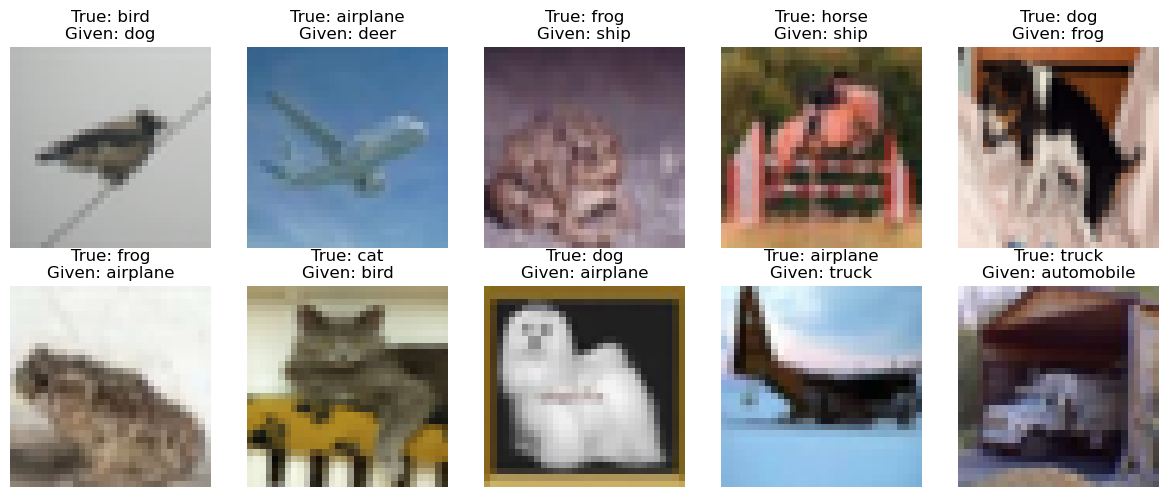

In [55]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for ax, idx in zip(axes.flat, noisy_indices[:10]):

    image, _ = full_dataset[idx]

    image = image * 0.5 + 0.5

    original = full_dataset.classes[original_labels[idx]]
    modified = full_dataset.classes[modified_labels[idx]]

    ax.imshow(image.permute(1, 2, 0).numpy())

    ax.set_title(f"True: {original}\nGiven: {modified}")

    ax.axis("off")

plt.tight_layout()
plt.savefig("figures/q1b_noisy_labels.png", dpi=300)
plt.show()

In [56]:
class LargeMLP(nn.Module):

    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Flatten(),

            nn.Linear(3072, 1024),
            nn.ReLU(),

            nn.Linear(1024, 1024),
            nn.ReLU(),

            nn.Linear(1024, 1024),
            nn.ReLU(),

            nn.Linear(1024, 1024),
            nn.ReLU(),

            nn.Linear(1024, 1024),
            nn.ReLU(),

            nn.Linear(1024, 10)
        )

    def forward(self, x):
        return self.network(x)

In [57]:
torch.manual_seed(seed)
torch.cuda.manual_seed_all(seed)

model_mem = LargeMLP().to(device)

optimizer_mem = optim.Adam(
    model_mem.parameters(),
    lr=0.001
)

In [58]:
epochs_mem = 100

In [59]:
print(model_mem)
print("Parameters:", count_parameters(model_mem))

LargeMLP(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3072, out_features=1024, bias=True)
    (2): ReLU()
    (3): Linear(in_features=1024, out_features=1024, bias=True)
    (4): ReLU()
    (5): Linear(in_features=1024, out_features=1024, bias=True)
    (6): ReLU()
    (7): Linear(in_features=1024, out_features=1024, bias=True)
    (8): ReLU()
    (9): Linear(in_features=1024, out_features=1024, bias=True)
    (10): ReLU()
    (11): Linear(in_features=1024, out_features=10, bias=True)
  )
)
Parameters: 7355402


In [60]:
config_mem = {
    "seed": seed,
    "architecture": [3072, 1024, 1024, 1024, 1024, 1024, 10],
    "parameters": count_parameters(model_mem),
    "noisy_fraction": noisy_fraction,
    "optimizer": "Adam",
    "learning_rate": 0.001,
    "batch_size": batch_size,
    "initial_epochs": epochs_mem,
    "memorisation_target_accuracy": 90
}

with open("results/q1b_config.json", "w") as f:
    json.dump(config_mem, f, indent=4)

In [61]:
generator_mem = torch.Generator()
generator_mem.manual_seed(seed)

mem_train_loader = DataLoader(
    memorisation_dataset,
    batch_size=batch_size,
    shuffle=True,
    generator=generator_mem
)

clean_train_loader = DataLoader(
    clean_train_dataset,
    batch_size=batch_size,
    shuffle=False
)

noisy_train_loader = DataLoader(
    noisy_train_dataset,
    batch_size=batch_size,
    shuffle=False
)

In [62]:
clean_loss, clean_acc = evaluate(model_mem, clean_train_loader)

noisy_loss, noisy_acc = evaluate(model_mem, noisy_train_loader)

val_loss, val_acc = evaluate(model_mem, val_loader)

history_mem = [{
    "epoch": 0,
    "clean_loss": clean_loss,
    "clean_accuracy": clean_acc,
    "noisy_loss": noisy_loss,
    "noisy_accuracy": noisy_acc,
    "val_loss": val_loss,
    "val_accuracy": val_acc
}]

print("Initial clean accuracy:", clean_acc)
print("Initial noisy accuracy:", noisy_acc)
print("Initial validation accuracy:", val_acc)

Initial clean accuracy: 9.834920634920636
Initial noisy accuracy: 10.051851851851852
Initial validation accuracy: 10.0


In [63]:
def train_memorisation(num_epochs):

    start_epoch = history_mem[-1]["epoch"]

    for epoch in range(start_epoch + 1,
                       start_epoch + num_epochs + 1):

        model_mem.train()

        for images, labels in mem_train_loader:

            images = images.to(device)
            labels = labels.to(device)

            optimizer_mem.zero_grad()

            outputs = model_mem(images)

            loss = criterion(outputs, labels)

            loss.backward()

            optimizer_mem.step()

        clean_loss, clean_acc = evaluate(
            model_mem, clean_train_loader
        )

        noisy_loss, noisy_acc = evaluate(
            model_mem, noisy_train_loader
        )

        val_loss, val_acc = evaluate(
            model_mem, val_loader
        )

        history_mem.append({
            "epoch": epoch,
            "clean_loss": clean_loss,
            "clean_accuracy": clean_acc,
            "noisy_loss": noisy_loss,
            "noisy_accuracy": noisy_acc,
            "val_loss": val_loss,
            "val_accuracy": val_acc
        })

        print(
            f"Epoch {epoch:3d} | "
            f"Clean Acc: {clean_acc:.2f}% | "
            f"Noisy Acc: {noisy_acc:.2f}% | "
            f"Val Acc: {val_acc:.2f}%"
        )

    pd.DataFrame(history_mem).to_csv(
        "results/q1b_history.csv", index=False
    )

    torch.save(
        model_mem.state_dict(),
        "checkpoints/q1b_memorisation.pth"
    )

In [64]:
start_time_mem = time.time()

train_memorisation(epochs_mem)

print(
    "Training time:",
    round(time.time() - start_time_mem, 2),
    "seconds"
)

Epoch   1 | Clean Acc: 38.15% | Noisy Acc: 7.68% | Val Acc: 35.58%
Epoch   2 | Clean Acc: 44.03% | Noisy Acc: 7.68% | Val Acc: 40.92%
Epoch   3 | Clean Acc: 48.35% | Noisy Acc: 8.26% | Val Acc: 43.46%
Epoch   4 | Clean Acc: 51.87% | Noisy Acc: 8.57% | Val Acc: 45.78%
Epoch   5 | Clean Acc: 54.06% | Noisy Acc: 9.36% | Val Acc: 45.54%
Epoch   6 | Clean Acc: 57.90% | Noisy Acc: 10.53% | Val Acc: 47.10%
Epoch   7 | Clean Acc: 60.90% | Noisy Acc: 11.50% | Val Acc: 47.70%
Epoch   8 | Clean Acc: 62.90% | Noisy Acc: 13.00% | Val Acc: 46.68%
Epoch   9 | Clean Acc: 64.98% | Noisy Acc: 14.77% | Val Acc: 46.92%
Epoch  10 | Clean Acc: 68.43% | Noisy Acc: 17.04% | Val Acc: 47.88%
Epoch  11 | Clean Acc: 68.96% | Noisy Acc: 19.40% | Val Acc: 47.28%
Epoch  12 | Clean Acc: 72.85% | Noisy Acc: 22.43% | Val Acc: 46.66%
Epoch  13 | Clean Acc: 74.02% | Noisy Acc: 25.53% | Val Acc: 45.60%
Epoch  14 | Clean Acc: 76.72% | Noisy Acc: 28.13% | Val Acc: 46.36%
Epoch  15 | Clean Acc: 78.67% | Noisy Acc: 32.86% | V

In [65]:
print("Final noisy accuracy:",
      history_mem[-1]["noisy_accuracy"])

print("Maximum noisy accuracy:",
      max(row["noisy_accuracy"] for row in history_mem))

Final noisy accuracy: 94.71111111111111
Maximum noisy accuracy: 94.71111111111111


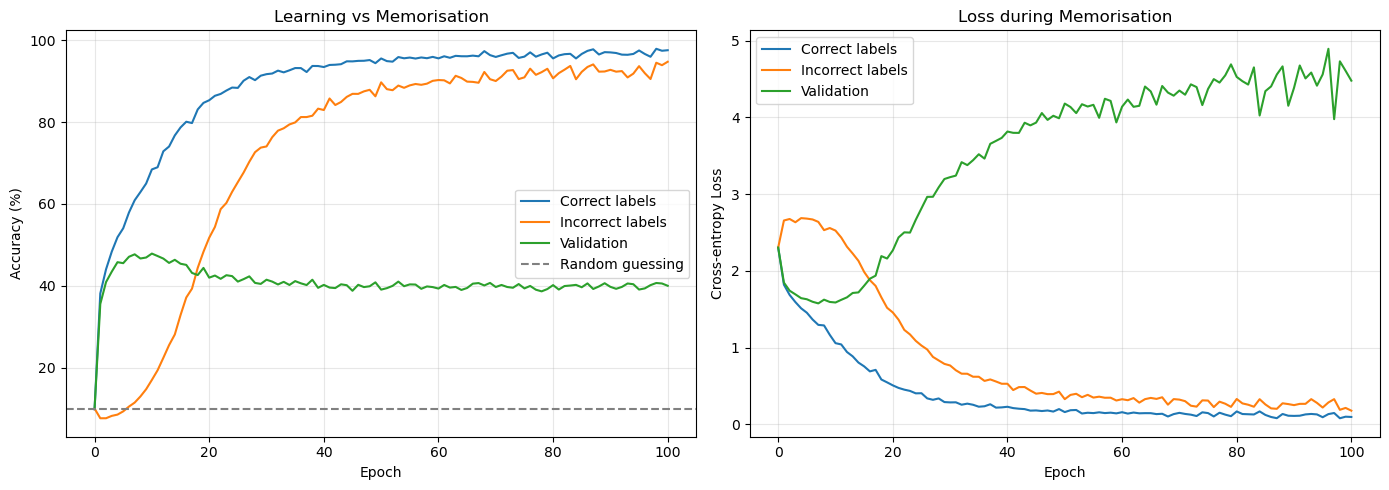

In [66]:
history_mem_df = pd.DataFrame(history_mem)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy curves

axes[0].plot(
    history_mem_df["epoch"],
    history_mem_df["clean_accuracy"],
    label="Correct labels"
)

axes[0].plot(
    history_mem_df["epoch"],
    history_mem_df["noisy_accuracy"],
    label="Incorrect labels"
)

axes[0].plot(
    history_mem_df["epoch"],
    history_mem_df["val_accuracy"],
    label="Validation"
)

axes[0].axhline(
    y=10, linestyle="--", color="gray",
    label="Random guessing"
)

axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy (%)")
axes[0].set_title("Learning vs Memorisation")
axes[0].legend()
axes[0].grid(alpha=0.3)

# Loss curves

axes[1].plot(
    history_mem_df["epoch"],
    history_mem_df["clean_loss"],
    label="Correct labels"
)

axes[1].plot(
    history_mem_df["epoch"],
    history_mem_df["noisy_loss"],
    label="Incorrect labels"
)

axes[1].plot(
    history_mem_df["epoch"],
    history_mem_df["val_loss"],
    label="Validation"
)

axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Cross-entropy Loss")
axes[1].set_title("Loss during Memorisation")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "figures/q1b_memorisation_curves.png",
    dpi=300
)

plt.show()

In [67]:
selected_epochs = [
    0, 1, 5, 10, 20, 30, 50, 75, 100,
    int(history_mem_df["epoch"].max())
]

trajectory_table = history_mem_df[
    history_mem_df["epoch"].isin(selected_epochs)
]

display(
    trajectory_table[
        [
            "epoch",
            "clean_accuracy",
            "noisy_accuracy",
            "val_accuracy"
        ]
    ].round(2)
)

trajectory_table.to_csv(
    "results/q1b_trajectory_table.csv",
    index=False
)

,epoch,clean_accuracy,noisy_accuracy,val_accuracy
0,0,9.83,10.05,10.00
1,1,38.15,7.68,35.58
5,5,54.06,9.36,45.54
10,10,68.43,17.04,47.88
20,20,85.31,51.74,42.00
30,30,91.68,74.04,41.50
50,50,95.51,89.68,39.08
75,75,95.96,90.90,39.38
100,100,97.52,94.71,40.02


In [68]:
best_val_row = history_mem_df.loc[
    history_mem_df["val_accuracy"].idxmax()
]

final_row = history_mem_df.iloc[-1]

print("Best validation epoch:",
      int(best_val_row["epoch"]))

print("Best validation accuracy:",
      round(best_val_row["val_accuracy"], 2))

print("Noisy accuracy at best validation epoch:",
      round(best_val_row["noisy_accuracy"], 2))

print("Final clean accuracy:",
      round(final_row["clean_accuracy"], 2))

print("Final noisy accuracy:",
      round(final_row["noisy_accuracy"], 2))

print("Final validation accuracy:",
      round(final_row["val_accuracy"], 2))

Best validation epoch: 10
Best validation accuracy: 47.88
Noisy accuracy at best validation epoch: 17.04
Final clean accuracy: 97.52
Final noisy accuracy: 94.71
Final validation accuracy: 40.02


# Q2(a) - Comparing CNN and MLP

In [69]:
class CNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.ReLU(),

            nn.Conv2d(256, 256, kernel_size=3, padding=1),
            nn.ReLU(),

            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Flatten(),

            nn.Linear(256, 10)
        )

    def forward(self, x):
        return self.network(x)

In [70]:
torch.manual_seed(seed)
torch.cuda.manual_seed_all(seed)

model_cnn = CNN().to(device)

mlp_params = count_parameters(model_sgd)
cnn_params = count_parameters(model_cnn)

difference = abs(mlp_params - cnn_params) / mlp_params * 100

print("MLP parameters:", mlp_params)
print("CNN parameters:", cnn_params)
print("Parameter difference:", round(difference, 2), "%")

MLP parameters: 1052426
CNN parameters: 963466
Parameter difference: 8.45 %


In [71]:
optimizer_cnn = optim.SGD(
    model_cnn.parameters(),
    lr=0.01,
    momentum=0.9
)

In [72]:
config_cnn = {
    "seed": seed,
    "model": "CNN",
    "channels": [3, 64, 128, 256, 256],
    "kernel_size": 3,
    "parameters": cnn_params,
    "optimizer": "SGD",
    "learning_rate": 0.01,
    "momentum": 0.9,
    "epochs": epochs,
    "batch_size": batch_size,
    "mlp_baseline": "q1a_sgd",
    "parameter_difference_percent": difference,
    "checkpoint_selection": "Highest validation accuracy"
}

with open("results/q2a_config.json", "w") as f:
    json.dump(config_cnn, f, indent=4)

In [73]:
history_cnn, time_cnn = train_model(
    model_cnn,
    optimizer_cnn,
    "q2a_cnn"
)

Epoch 1/30 | Train Loss: 2.0943 | Train Acc: 20.92% | Val Loss: 1.8475 | Val Acc: 28.52%
Epoch 2/30 | Train Loss: 1.7089 | Train Acc: 35.64% | Val Loss: 1.6052 | Val Acc: 38.98%
Epoch 3/30 | Train Loss: 1.5689 | Train Acc: 41.14% | Val Loss: 1.5114 | Val Acc: 42.50%
Epoch 4/30 | Train Loss: 1.4557 | Train Acc: 46.40% | Val Loss: 1.3894 | Val Acc: 49.14%
Epoch 5/30 | Train Loss: 1.3385 | Train Acc: 51.59% | Val Loss: 1.3017 | Val Acc: 53.38%
Epoch 6/30 | Train Loss: 1.2724 | Train Acc: 54.06% | Val Loss: 1.2155 | Val Acc: 55.74%
Epoch 7/30 | Train Loss: 1.1818 | Train Acc: 57.48% | Val Loss: 1.1437 | Val Acc: 58.64%
Epoch 8/30 | Train Loss: 1.1067 | Train Acc: 60.33% | Val Loss: 1.1513 | Val Acc: 58.70%
Epoch 9/30 | Train Loss: 1.0545 | Train Acc: 62.30% | Val Loss: 1.0287 | Val Acc: 63.24%
Epoch 10/30 | Train Loss: 1.0078 | Train Acc: 64.00% | Val Loss: 1.0724 | Val Acc: 62.28%
Epoch 11/30 | Train Loss: 0.9652 | Train Acc: 65.54% | Val Loss: 0.9576 | Val Acc: 66.52%
Epoch 12/30 | Train

In [74]:
best_cnn = history_cnn.loc[
    history_cnn["val_accuracy"].idxmax()
]

best_mlp = history_sgd.loc[
    history_sgd["val_accuracy"].idxmax()
]

q2a_results = pd.DataFrame({
    "Model": ["MLP", "CNN"],
    "Parameters": [mlp_params, cnn_params],

    "Best Epoch": [
        int(best_mlp["epoch"]),
        int(best_cnn["epoch"])
    ],

    "Training Accuracy (%)": [
        best_mlp["train_accuracy"],
        best_cnn["train_accuracy"]
    ],

    "Validation Accuracy (%)": [
        best_mlp["val_accuracy"],
        best_cnn["val_accuracy"]
    ],

    "Validation Loss": [
        best_mlp["val_loss"],
        best_cnn["val_loss"]
    ],

    "Training Time (s)": [
        time_sgd,
        time_cnn
    ]
})

display(q2a_results.round(4))

q2a_results.to_csv(
    "results/q2a_comparison.csv",
    index=False
)

,Model,Parameters,Best Epoch,Training Accuracy (%),Validation Accuracy (%),Validation Loss,Training Time (s)
0,MLP,1052426,16,72.7000,55.08,1.4580,176.8123
1,CNN,963466,28,82.7622,77.86,0.6548,283.0432


In [75]:
cnn_test_loss, cnn_test_accuracy = evaluate(
    model_cnn, test_loader
)

q2a_results["Test Accuracy (%)"] = [
    sgd_test_accuracy,
    cnn_test_accuracy
]

display(q2a_results.round(4))

q2a_results.to_csv(
    "results/q2a_final_results.csv",
    index=False
)

,Model,Parameters,Best Epoch,Training Accuracy (%),Validation Accuracy (%),Validation Loss,Training Time (s),Test Accuracy (%)
0,MLP,1052426,16,72.7000,55.08,1.4580,176.8123,54.03
1,CNN,963466,28,82.7622,77.86,0.6548,283.0432,77.65


## Question is completed but i am trying to get the best accuracy CNN model as there is still scope of improvement present we didn't trained more epochs here because MLP also got 30 epochs

In [76]:
model_cnn_best = copy.deepcopy(model_cnn)

optimizer_best = optim.SGD(
    model_cnn_best.parameters(),
    lr=0.005,
    momentum=0.9
)

max_extra_epochs = 70
patience = 10

In [77]:
scheduler_best = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_best,
    mode="max",
    factor=0.5,
    patience=3
)

In [78]:
best_loss, best_accuracy = evaluate(
    model_cnn_best, val_loader
)

initial_accuracy = best_accuracy

counter = 0
best_extra_epoch = 0

torch.save(
    model_cnn_best.state_dict(),
    "checkpoints/cnn_best.pth"
)

history_extra = []

train_loader_extra = get_train_loader()

print("Starting validation accuracy:", best_accuracy)

Starting validation accuracy: 77.86


In [79]:
for epoch in range(max_extra_epochs):

    model_cnn_best.train()

    total_loss = 0
    correct = 0
    total = 0

    current_lr = optimizer_best.param_groups[0]["lr"]

    for images, labels in train_loader_extra:

        images = images.to(device)
        labels = labels.to(device)

        optimizer_best.zero_grad()

        outputs = model_cnn_best(images)

        loss = criterion(outputs, labels)

        loss.backward()
        optimizer_best.step()

        total_loss += loss.item() * labels.size(0)

        correct += (outputs.argmax(dim=1) == labels).sum().item()

        total += labels.size(0)

    train_loss = total_loss / total
    train_accuracy = 100 * correct / total

    val_loss, val_accuracy = evaluate(
        model_cnn_best, val_loader
    )

    history_extra.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "val_loss": val_loss,
        "val_accuracy": val_accuracy,
        "learning_rate": current_lr
    })

    if val_accuracy > best_accuracy:

        best_accuracy = val_accuracy
        best_extra_epoch = epoch + 1
        counter = 0

        torch.save(
            model_cnn_best.state_dict(),
            "checkpoints/cnn_best.pth"
        )

    else:
        counter += 1

    scheduler_best.step(val_accuracy)

    print(
        f"Epoch {epoch+1}/{max_extra_epochs} | "
        f"Train Acc: {train_accuracy:.2f}% | "
        f"Val Acc: {val_accuracy:.2f}% | "
        f"Best Val: {best_accuracy:.2f}% | "
        f"LR: {current_lr:.6f} | "
        f"Patience: {counter}/{patience}"
    )

    if counter >= patience:
        print("Early stopping at epoch", epoch + 1)
        break

Epoch 1/70 | Train Acc: 85.27% | Val Acc: 79.98% | Best Val: 79.98% | LR: 0.005000 | Patience: 0/10
Epoch 2/70 | Train Acc: 85.93% | Val Acc: 79.00% | Best Val: 79.98% | LR: 0.005000 | Patience: 1/10
Epoch 3/70 | Train Acc: 86.12% | Val Acc: 78.02% | Best Val: 79.98% | LR: 0.005000 | Patience: 2/10
Epoch 4/70 | Train Acc: 86.47% | Val Acc: 79.84% | Best Val: 79.98% | LR: 0.005000 | Patience: 3/10
Epoch 5/70 | Train Acc: 87.14% | Val Acc: 80.20% | Best Val: 80.20% | LR: 0.005000 | Patience: 0/10
Epoch 6/70 | Train Acc: 87.56% | Val Acc: 79.88% | Best Val: 80.20% | LR: 0.005000 | Patience: 1/10
Epoch 7/70 | Train Acc: 87.98% | Val Acc: 79.22% | Best Val: 80.20% | LR: 0.005000 | Patience: 2/10
Epoch 8/70 | Train Acc: 88.19% | Val Acc: 79.84% | Best Val: 80.20% | LR: 0.005000 | Patience: 3/10
Epoch 9/70 | Train Acc: 88.54% | Val Acc: 79.68% | Best Val: 80.20% | LR: 0.005000 | Patience: 4/10
Epoch 10/70 | Train Acc: 90.33% | Val Acc: 80.38% | Best Val: 80.38% | LR: 0.002500 | Patience: 0/10

In [80]:
model_cnn_best.load_state_dict(
    torch.load(
        "checkpoints/cnn_best.pth",
        map_location=device
    )
)

final_val_loss, final_val_accuracy = evaluate(
    model_cnn_best, val_loader
)

print("Original validation accuracy:", initial_accuracy)
print("Best validation accuracy:", final_val_accuracy)
print("Best additional epoch:", best_extra_epoch)

print("Improvement:",
      round(final_val_accuracy - initial_accuracy, 2),
      "percentage points")

Original validation accuracy: 77.86
Best validation accuracy: 81.56
Best additional epoch: 31
Improvement: 3.7 percentage points


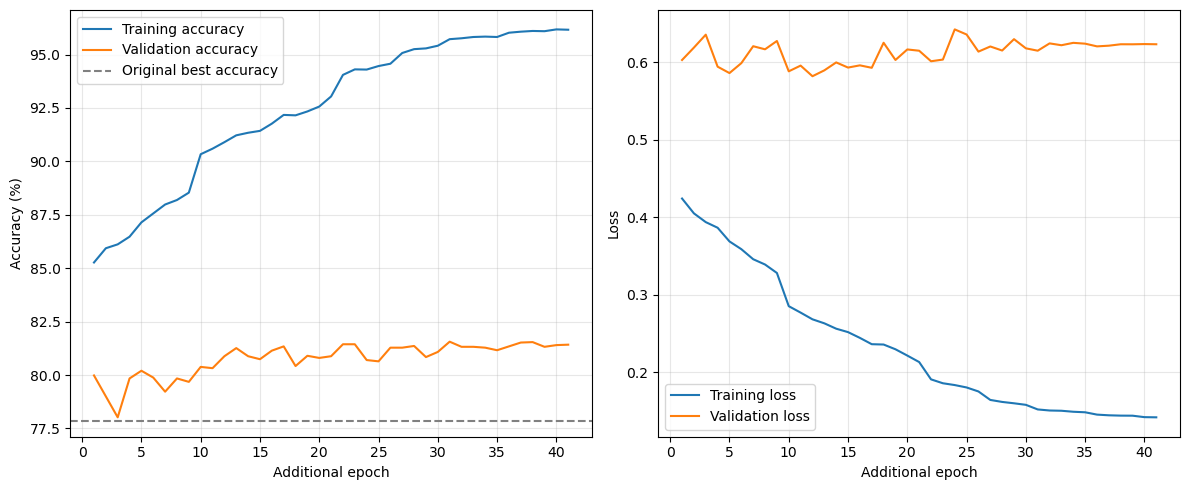

In [81]:
history_extra_df = pd.DataFrame(history_extra)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].plot(
    history_extra_df["epoch"],
    history_extra_df["train_accuracy"],
    label="Training accuracy"
)

axes[0].plot(
    history_extra_df["epoch"],
    history_extra_df["val_accuracy"],
    label="Validation accuracy"
)

axes[0].axhline(
    initial_accuracy,
    linestyle="--",
    color="gray",
    label="Original best accuracy"
)

axes[0].set_xlabel("Additional epoch")
axes[0].set_ylabel("Accuracy (%)")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(
    history_extra_df["epoch"],
    history_extra_df["train_loss"],
    label="Training loss"
)

axes[1].plot(
    history_extra_df["epoch"],
    history_extra_df["val_loss"],
    label="Validation loss"
)

axes[1].set_xlabel("Additional epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("figures/cnn_extended_training.png", dpi=300)
plt.show()

history_extra_df.to_csv(
    "results/cnn_extended_history.csv",
    index=False
)

In [82]:
config_extra = {
    "starting_checkpoint": "q2a_cnn.pth",
    "starting_epoch": int(best_cnn["epoch"]),
    "seed": seed,
    "optimizer": "SGD",
    "initial_learning_rate": 0.005,
    "momentum": 0.9,
    "scheduler_factor": 0.5,
    "scheduler_patience": 3,
    "early_stopping_patience": patience,
    "max_extra_epochs": max_extra_epochs,
    "actual_extra_epochs": len(history_extra_df),
    "best_extra_epoch": best_extra_epoch,
    "best_validation_accuracy": final_val_accuracy
}

with open("results/cnn_extended_config.json", "w") as f:
    json.dump(config_extra, f, indent=4)

# Q2(b) - Effect of Spatial Pixel Shuffling

The spatial positions of CIFAR10 pixels are rearranged using
one fixed random permutation without changing their values.

We expect the CNN to suffer a larger decrease in accuracy
than the MLP because CNNs rely on local spatial relationships
between pixels.

In [83]:
generator_shuffle = torch.Generator()
generator_shuffle.manual_seed(seed)

pixel_perm = torch.randperm(
    32 * 32,
    generator=generator_shuffle
)

print("Number of pixel positions:", len(pixel_perm))
print("First 10 shuffled positions:", pixel_perm[:10])

np.save(
    "results/q2b_pixel_permutation.npy",
    pixel_perm.numpy()
)

Number of pixel positions: 1024
First 10 shuffled positions: tensor([617, 243, 586, 564, 984, 492, 388, 454, 818, 359])


In [84]:
from torch.utils.data import Dataset

class ShuffledDataset(Dataset):

    def __init__(self, dataset, permutation):
        self.dataset = dataset
        self.permutation = permutation

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, index):

        image, label = self.dataset[index]

        image = image.reshape(3, 1024)

        image = image[:, self.permutation]

        image = image.reshape(3, 32, 32)

        return image, label

In [85]:
shuffled_train_dataset = ShuffledDataset(
    train_dataset, pixel_perm
)

shuffled_val_dataset = ShuffledDataset(
    val_dataset, pixel_perm
)

shuffled_test_dataset = ShuffledDataset(
    test_dataset, pixel_perm
)

print("Training images:", len(shuffled_train_dataset))
print("Validation images:", len(shuffled_val_dataset))
print("Testing images:", len(shuffled_test_dataset))

Training images: 45000
Validation images: 5000
Testing images: 10000


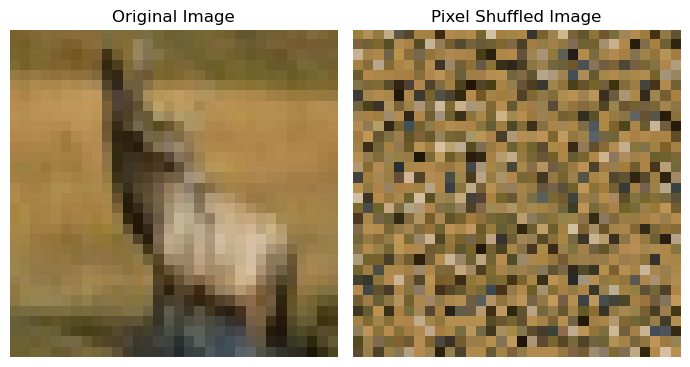

In [86]:
image, label = train_dataset[0]
shuffled_image, shuffled_label = shuffled_train_dataset[0]

# Verify that the pixel values are unchanged
assert torch.equal(
    image.reshape(3, -1).sort(dim=1).values,
    shuffled_image.reshape(3, -1).sort(dim=1).values
)

assert label == shuffled_label

fig, axes = plt.subplots(1, 2, figsize=(7, 4))

axes[0].imshow(
    (image * 0.5 + 0.5).permute(1, 2, 0).numpy()
)

axes[0].set_title("Original Image")
axes[0].axis("off")

axes[1].imshow(
    (shuffled_image * 0.5 + 0.5).permute(1, 2, 0).numpy()
)

axes[1].set_title("Pixel Shuffled Image")
axes[1].axis("off")

plt.tight_layout()
plt.savefig("figures/q2b_pixel_shuffle.png", dpi=300)
plt.show()

In [87]:
torch.manual_seed(seed)
torch.cuda.manual_seed_all(seed)

model_mlp_shuffled = MLP().to(device)

torch.manual_seed(seed)
torch.cuda.manual_seed_all(seed)

model_cnn_shuffled = CNN().to(device)

optimizer_mlp_shuffled = optim.SGD(
    model_mlp_shuffled.parameters(),
    lr=0.01,
    momentum=0.9
)

optimizer_cnn_shuffled = optim.SGD(
    model_cnn_shuffled.parameters(),
    lr=0.01,
    momentum=0.9
)

print("MLP parameters:", count_parameters(model_mlp_shuffled))
print("CNN parameters:", count_parameters(model_cnn_shuffled))

MLP parameters: 1052426
CNN parameters: 963466


In [88]:
def train_spatial_model(model, optimizer, name,
                        training_data, validation_data):

    generator = torch.Generator()
    generator.manual_seed(seed)

    train_loader = DataLoader(
        training_data,
        batch_size=batch_size,
        shuffle=True,
        generator=generator
    )

    validation_loader = DataLoader(
        validation_data,
        batch_size=batch_size,
        shuffle=False
    )

    history = []
    best_val_accuracy = -1
    best_epoch = 0

    start_time = time.time()

    for epoch in range(30):

        model.train()

        total_loss = 0
        correct = 0
        total = 0

        for images, labels in train_loader:

            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)

            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

            total_loss += loss.item() * labels.size(0)

            correct += (outputs.argmax(dim=1) == labels).sum().item()

            total += labels.size(0)

        train_loss = total_loss / total
        train_accuracy = 100 * correct / total

        val_loss, val_accuracy = evaluate(
            model, validation_loader
        )

        history.append({
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "train_accuracy": train_accuracy,
            "val_loss": val_loss,
            "val_accuracy": val_accuracy
        })

        if val_accuracy > best_val_accuracy:

            best_val_accuracy = val_accuracy
            best_epoch = epoch + 1

            torch.save(
                model.state_dict(),
                f"checkpoints/{name}.pth"
            )

        print(
            f"Epoch {epoch+1}/30 | "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_accuracy:.2f}% | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_accuracy:.2f}%"
        )

    elapsed = time.time() - start_time

    history = pd.DataFrame(history)

    history.to_csv(
        f"results/{name}_history.csv",
        index=False
    )

    model.load_state_dict(
        torch.load(
            f"checkpoints/{name}.pth",
            map_location=device
        )
    )

    print("Best validation accuracy:", best_val_accuracy)
    print("Best epoch:", best_epoch)
    print("Training time:", round(elapsed, 2), "seconds")

    return history, elapsed

In [89]:
config_shuffle = {
    "seed": seed,
    "transformation": "Fixed spatial pixel permutation",
    "permutation_file": "results/q2b_pixel_permutation.npy",
    "rgb_channels_kept_together": True,
    "epochs": 30,
    "batch_size": batch_size,
    "optimizer": "SGD",
    "learning_rate": 0.01,
    "momentum": 0.9,
    "mlp_parameters": count_parameters(model_mlp_shuffled),
    "cnn_parameters": count_parameters(model_cnn_shuffled),
    "checkpoint_selection": "Highest validation accuracy"
}

with open("results/q2b_config.json", "w") as f:
    json.dump(config_shuffle, f, indent=4)

In [90]:
history_mlp_shuffled, time_mlp_shuffled = train_spatial_model(
    model_mlp_shuffled,
    optimizer_mlp_shuffled,
    "q2b_mlp_shuffled",
    shuffled_train_dataset,
    shuffled_val_dataset
)

Epoch 1/30 | Train Loss: 2.2662 | Train Acc: 14.70% | Val Loss: 2.0608 | Val Acc: 20.34%
Epoch 2/30 | Train Loss: 1.9093 | Train Acc: 28.37% | Val Loss: 1.7741 | Val Acc: 34.00%
Epoch 3/30 | Train Loss: 1.6504 | Train Acc: 40.04% | Val Loss: 1.5779 | Val Acc: 41.70%
Epoch 4/30 | Train Loss: 1.4948 | Train Acc: 46.51% | Val Loss: 1.5134 | Val Acc: 45.82%
Epoch 5/30 | Train Loss: 1.3942 | Train Acc: 49.79% | Val Loss: 1.4322 | Val Acc: 48.38%
Epoch 6/30 | Train Loss: 1.3064 | Train Acc: 53.23% | Val Loss: 1.3903 | Val Acc: 50.92%
Epoch 7/30 | Train Loss: 1.2355 | Train Acc: 55.67% | Val Loss: 1.3789 | Val Acc: 51.90%
Epoch 8/30 | Train Loss: 1.1721 | Train Acc: 58.17% | Val Loss: 1.3715 | Val Acc: 52.20%
Epoch 9/30 | Train Loss: 1.1148 | Train Acc: 60.17% | Val Loss: 1.3901 | Val Acc: 51.46%
Epoch 10/30 | Train Loss: 1.0666 | Train Acc: 61.92% | Val Loss: 1.3695 | Val Acc: 53.08%
Epoch 11/30 | Train Loss: 1.0074 | Train Acc: 63.78% | Val Loss: 1.3912 | Val Acc: 52.24%
Epoch 12/30 | Train

In [91]:
history_cnn_shuffled, time_cnn_shuffled = train_spatial_model(
    model_cnn_shuffled,
    optimizer_cnn_shuffled,
    "q2b_cnn_shuffled",
    shuffled_train_dataset,
    shuffled_val_dataset
)

Epoch 1/30 | Train Loss: 2.1014 | Train Acc: 21.04% | Val Loss: 1.9863 | Val Acc: 24.60%
Epoch 2/30 | Train Loss: 1.9701 | Train Acc: 26.22% | Val Loss: 1.9418 | Val Acc: 26.92%
Epoch 3/30 | Train Loss: 1.9351 | Train Acc: 27.72% | Val Loss: 1.9091 | Val Acc: 28.08%
Epoch 4/30 | Train Loss: 1.9088 | Train Acc: 28.87% | Val Loss: 1.8879 | Val Acc: 28.98%
Epoch 5/30 | Train Loss: 1.8806 | Train Acc: 30.04% | Val Loss: 1.8646 | Val Acc: 29.36%
Epoch 6/30 | Train Loss: 1.8540 | Train Acc: 30.78% | Val Loss: 1.9074 | Val Acc: 29.50%
Epoch 7/30 | Train Loss: 1.8302 | Train Acc: 31.69% | Val Loss: 1.9067 | Val Acc: 29.72%
Epoch 8/30 | Train Loss: 1.8122 | Train Acc: 32.45% | Val Loss: 1.8016 | Val Acc: 32.78%
Epoch 9/30 | Train Loss: 1.7849 | Train Acc: 33.54% | Val Loss: 1.8167 | Val Acc: 30.86%
Epoch 10/30 | Train Loss: 1.7663 | Train Acc: 34.51% | Val Loss: 1.7439 | Val Acc: 35.20%
Epoch 11/30 | Train Loss: 1.7367 | Train Acc: 35.88% | Val Loss: 1.7863 | Val Acc: 31.90%
Epoch 12/30 | Train

In [92]:
q2b_results = pd.DataFrame({
    "Model": ["MLP", "CNN"],

    "Parameters": [
        count_parameters(model_mlp_shuffled),
        count_parameters(model_cnn_shuffled)
    ],

    "Clean Val Accuracy (%)": [
        history_sgd["val_accuracy"].max(),
        history_cnn["val_accuracy"].max()
    ],

    "Shuffled Val Accuracy (%)": [
        history_mlp_shuffled["val_accuracy"].max(),
        history_cnn_shuffled["val_accuracy"].max()
    ]
})

q2b_results["Accuracy Drop (pp)"] = (
    q2b_results["Clean Val Accuracy (%)"] -
    q2b_results["Shuffled Val Accuracy (%)"]
)

display(q2b_results.round(2))

q2b_results.to_csv(
    "results/q2b_validation_comparison.csv",
    index=False
)

,Model,Parameters,Clean Val Accuracy (%),Shuffled Val Accuracy (%),Accuracy Drop (pp)
0,MLP,1052426,55.08,54.34,0.74
1,CNN,963466,77.86,45.82,32.04


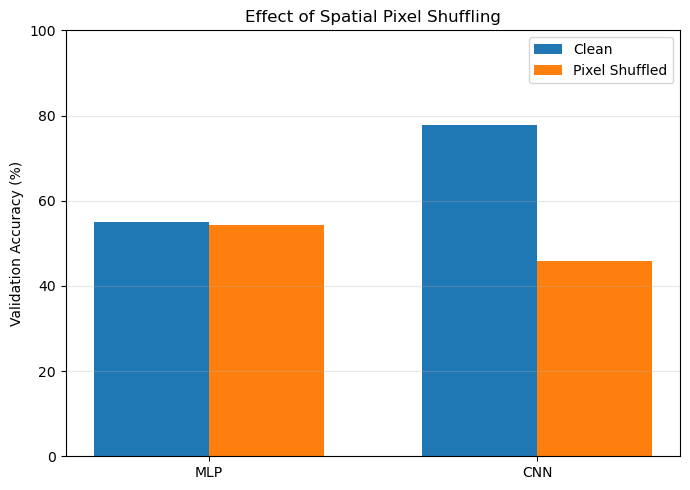

In [93]:
plt.figure(figsize=(7, 5))

x = np.arange(2)
width = 0.35

plt.bar(
    x - width / 2,
    q2b_results["Clean Val Accuracy (%)"],
    width,
    label="Clean"
)

plt.bar(
    x + width / 2,
    q2b_results["Shuffled Val Accuracy (%)"],
    width,
    label="Pixel Shuffled"
)

plt.xticks(x, ["MLP", "CNN"])
plt.ylabel("Validation Accuracy (%)")
plt.title("Effect of Spatial Pixel Shuffling")
plt.ylim(0, 100)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("figures/q2b_comparison.png", dpi=300)
plt.show()

In [94]:
shuffled_test_loader = DataLoader(
    shuffled_test_dataset,
    batch_size=batch_size,
    shuffle=False
)

mlp_shuffle_test_loss, mlp_shuffle_test_acc = evaluate(
    model_mlp_shuffled,
    shuffled_test_loader
)

cnn_shuffle_test_loss, cnn_shuffle_test_acc = evaluate(
    model_cnn_shuffled,
    shuffled_test_loader
)

q2b_results["Clean Test Accuracy (%)"] = [
    sgd_test_accuracy,
    cnn_test_accuracy
]

q2b_results["Shuffled Test Accuracy (%)"] = [
    mlp_shuffle_test_acc,
    cnn_shuffle_test_acc
]

q2b_results["Test Accuracy Drop (pp)"] = (
    q2b_results["Clean Test Accuracy (%)"] -
    q2b_results["Shuffled Test Accuracy (%)"]
)

display(q2b_results.round(2))

q2b_results.to_csv(
    "results/q2b_final_results.csv",
    index=False
)

,Model,Parameters,Clean Val Accuracy (%),Shuffled Val Accuracy (%),Accuracy Drop (pp),Clean Test Accuracy (%),Shuffled Test Accuracy (%),Test Accuracy Drop (pp)
0,MLP,1052426,55.08,54.34,0.74,54.03,53.82,0.21
1,CNN,963466,77.86,45.82,32.04,77.65,46.49,31.16


# Q2(c) - Effect of Patch Shuffling

This experiment investigates whether the CNN relies more on
local visual features or the global spatial arrangement of images.

Each image is divided into sixteen 8 x 8 patches.
The patches are shuffled without changing the pixels inside them.

We expect the CNN to perform better on patch-shuffled images
than on pixel-shuffled images.

In [95]:
patch_size = 8
patches_per_side = 32 // patch_size

generator_patch = torch.Generator()
generator_patch.manual_seed(seed)

patch_perm = torch.randperm(
    16, generator=generator_patch
)

print("Original patch positions:", torch.arange(16))
print("Shuffled patch positions:", patch_perm)

Original patch positions: tensor([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15])
Shuffled patch positions: tensor([ 9,  6, 12,  2,  3,  8, 10, 13,  1,  0, 14, 15,  4,  5, 11,  7])


In [96]:
pixel_grid = torch.arange(1024).reshape(32, 32)

shuffled_grid = torch.empty_like(pixel_grid)

for new_pos, old_pos in enumerate(patch_perm.tolist()):

    new_row, new_col = divmod(new_pos, 4)

    old_row, old_col = divmod(old_pos, 4)

    original_patch = pixel_grid[
        old_row * 8 : (old_row + 1) * 8,
        old_col * 8 : (old_col + 1) * 8
    ]

    shuffled_grid[
        new_row * 8 : (new_row + 1) * 8,
        new_col * 8 : (new_col + 1) * 8
    ] = original_patch

patch_pixel_perm = shuffled_grid.flatten()

assert torch.equal(
    patch_pixel_perm.sort().values,
    torch.arange(1024)
)

np.save(
    "results/q2c_patch_permutation.npy",
    patch_pixel_perm.numpy()
)

In [97]:
patch_train_dataset = ShuffledDataset(
    train_dataset, patch_pixel_perm
)

patch_val_dataset = ShuffledDataset(
    val_dataset, patch_pixel_perm
)

patch_test_dataset = ShuffledDataset(
    test_dataset, patch_pixel_perm
)

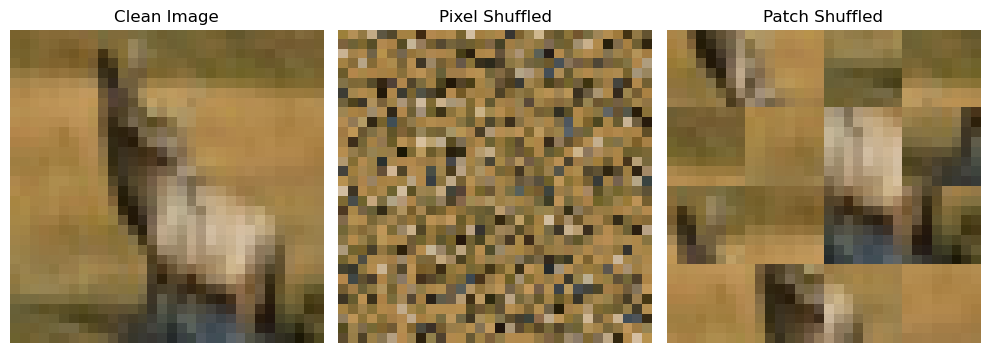

In [98]:
original_image, label = train_dataset[0]

pixel_image, _ = shuffled_train_dataset[0]

patch_image, _ = patch_train_dataset[0]

fig, axes = plt.subplots(1, 3, figsize=(10, 4))

images = [
    original_image,
    pixel_image,
    patch_image
]

titles = [
    "Clean Image",
    "Pixel Shuffled",
    "Patch Shuffled"
]

for ax, image, title in zip(axes, images, titles):

    ax.imshow(
        (image * 0.5 + 0.5).permute(1, 2, 0).numpy()
    )

    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.savefig("figures/q2c_transformations.png", dpi=300)
plt.show()

In [99]:
torch.manual_seed(seed)
torch.cuda.manual_seed_all(seed)

model_mlp_patch = MLP().to(device)

torch.manual_seed(seed)
torch.cuda.manual_seed_all(seed)

model_cnn_patch = CNN().to(device)

optimizer_mlp_patch = optim.SGD(
    model_mlp_patch.parameters(),
    lr=0.01,
    momentum=0.9
)

optimizer_cnn_patch = optim.SGD(
    model_cnn_patch.parameters(),
    lr=0.01,
    momentum=0.9
)

print("MLP parameters:", count_parameters(model_mlp_patch))
print("CNN parameters:", count_parameters(model_cnn_patch))

MLP parameters: 1052426
CNN parameters: 963466


In [100]:
config_patch = {
    "seed": seed,
    "transformation": "Fixed patch shuffling",
    "patch_size": 8,
    "number_of_patches": 16,
    "permutation_file": "results/q2c_patch_permutation.npy",
    "epochs": 30,
    "batch_size": batch_size,
    "optimizer": "SGD",
    "learning_rate": 0.01,
    "momentum": 0.9,
    "checkpoint_selection": "Highest validation accuracy"
}

with open("results/q2c_config.json", "w") as f:
    json.dump(config_patch, f, indent=4)

In [101]:
history_mlp_patch, time_mlp_patch = train_spatial_model(
    model_mlp_patch,
    optimizer_mlp_patch,
    "q2c_mlp_patch",
    patch_train_dataset,
    patch_val_dataset
)

Epoch 1/30 | Train Loss: 2.2530 | Train Acc: 15.02% | Val Loss: 2.0275 | Val Acc: 22.88%
Epoch 2/30 | Train Loss: 1.8795 | Train Acc: 29.30% | Val Loss: 1.7571 | Val Acc: 34.96%
Epoch 3/30 | Train Loss: 1.6356 | Train Acc: 40.65% | Val Loss: 1.5674 | Val Acc: 41.92%
Epoch 4/30 | Train Loss: 1.4857 | Train Acc: 46.49% | Val Loss: 1.5083 | Val Acc: 45.56%
Epoch 5/30 | Train Loss: 1.3869 | Train Acc: 50.36% | Val Loss: 1.4342 | Val Acc: 48.34%
Epoch 6/30 | Train Loss: 1.2997 | Train Acc: 53.57% | Val Loss: 1.4088 | Val Acc: 50.24%
Epoch 7/30 | Train Loss: 1.2316 | Train Acc: 56.09% | Val Loss: 1.3800 | Val Acc: 51.92%
Epoch 8/30 | Train Loss: 1.1697 | Train Acc: 58.31% | Val Loss: 1.3732 | Val Acc: 51.68%
Epoch 9/30 | Train Loss: 1.1104 | Train Acc: 60.48% | Val Loss: 1.3825 | Val Acc: 50.60%
Epoch 10/30 | Train Loss: 1.0593 | Train Acc: 62.39% | Val Loss: 1.3669 | Val Acc: 53.08%
Epoch 11/30 | Train Loss: 1.0037 | Train Acc: 64.46% | Val Loss: 1.4043 | Val Acc: 52.62%
Epoch 12/30 | Train

In [102]:
history_cnn_patch, time_cnn_patch = train_spatial_model(
    model_cnn_patch,
    optimizer_cnn_patch,
    "q2c_cnn_patch",
    patch_train_dataset,
    patch_val_dataset
)

Epoch 1/30 | Train Loss: 2.1203 | Train Acc: 20.25% | Val Loss: 1.9660 | Val Acc: 25.46%
Epoch 2/30 | Train Loss: 1.8594 | Train Acc: 29.39% | Val Loss: 1.7641 | Val Acc: 32.98%
Epoch 3/30 | Train Loss: 1.7432 | Train Acc: 34.55% | Val Loss: 1.6771 | Val Acc: 36.04%
Epoch 4/30 | Train Loss: 1.6470 | Train Acc: 38.18% | Val Loss: 1.6114 | Val Acc: 39.10%
Epoch 5/30 | Train Loss: 1.5626 | Train Acc: 41.88% | Val Loss: 1.5023 | Val Acc: 43.86%
Epoch 6/30 | Train Loss: 1.4979 | Train Acc: 44.68% | Val Loss: 1.4580 | Val Acc: 45.46%
Epoch 7/30 | Train Loss: 1.4495 | Train Acc: 46.69% | Val Loss: 1.4396 | Val Acc: 48.34%
Epoch 8/30 | Train Loss: 1.3879 | Train Acc: 49.41% | Val Loss: 1.4538 | Val Acc: 47.70%
Epoch 9/30 | Train Loss: 1.3321 | Train Acc: 51.35% | Val Loss: 1.3650 | Val Acc: 51.02%
Epoch 10/30 | Train Loss: 1.2977 | Train Acc: 52.76% | Val Loss: 1.2945 | Val Acc: 52.94%
Epoch 11/30 | Train Loss: 1.2489 | Train Acc: 54.57% | Val Loss: 1.2180 | Val Acc: 55.46%
Epoch 12/30 | Train

In [103]:
q2_validation = pd.DataFrame({
    "Model": ["MLP", "CNN"],

    "Clean": [
        history_sgd["val_accuracy"].max(),
        history_cnn["val_accuracy"].max()
    ],

    "Pixel Shuffled": [
        history_mlp_shuffled["val_accuracy"].max(),
        history_cnn_shuffled["val_accuracy"].max()
    ],

    "Patch Shuffled": [
        history_mlp_patch["val_accuracy"].max(),
        history_cnn_patch["val_accuracy"].max()
    ]
})

display(q2_validation.round(2))

q2_validation.to_csv(
    "results/q2_validation_comparison.csv",
    index=False
)

,Model,Clean,Pixel Shuffled,Patch Shuffled
0,MLP,55.08,54.34,54.08
1,CNN,77.86,45.82,67.56


In [104]:
def get_predictions(model, loader):

    model.eval()

    all_labels = []
    all_predictions = []
    all_confidences = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)

            outputs = model(images)

            probabilities = torch.softmax(
                outputs, dim=1
            )

            confidence, predictions = probabilities.max(dim=1)

            all_labels.extend(labels.numpy())

            all_predictions.extend(
                predictions.cpu().numpy()
            )

            all_confidences.extend(
                confidence.cpu().numpy()
            )

    return (
        np.array(all_labels),
        np.array(all_predictions),
        np.array(all_confidences)
    )

In [105]:
from sklearn.metrics import confusion_matrix

patch_test_loader = DataLoader(
    patch_test_dataset,
    batch_size=batch_size,
    shuffle=False
)

experiments = [
    ("Clean", "MLP", model_sgd, test_loader),
    ("Clean", "CNN", model_cnn, test_loader),

    ("Pixel Shuffled", "MLP", model_mlp_shuffled,
     shuffled_test_loader),

    ("Pixel Shuffled", "CNN", model_cnn_shuffled,
     shuffled_test_loader),

    ("Patch Shuffled", "MLP", model_mlp_patch,
     patch_test_loader),

    ("Patch Shuffled", "CNN", model_cnn_patch,
     patch_test_loader)
]

final_q2_results = []
confusion_matrices = {}

for condition, name, model, loader in experiments:

    labels, predictions, confidences = get_predictions(
        model, loader
    )

    correct = predictions == labels
    incorrect = predictions != labels

    accuracy = correct.mean() * 100

    mean_confidence = confidences.mean() * 100

    correct_confidence = confidences[correct].mean() * 100

    incorrect_confidence = confidences[incorrect].mean() * 100

    final_q2_results.append({
        "Condition": condition,
        "Model": name,
        "Parameters": count_parameters(model),
        "Test Accuracy (%)": accuracy,
        "Number of Errors": incorrect.sum(),
        "Mean Confidence (%)": mean_confidence,
        "Correct Confidence (%)": correct_confidence,
        "Incorrect Confidence (%)": incorrect_confidence
    })

    cm = confusion_matrix(
        labels, predictions, labels=np.arange(10)
    )

    confusion_matrices[(name, condition)] = cm

final_q2_df = pd.DataFrame(final_q2_results)

display(final_q2_df.round(2))

final_q2_df.to_csv(
    "results/q2_final_results.csv",
    index=False
)

,Condition,Model,Parameters,Test Accuracy (%),Number of Errors,Mean Confidence (%),Correct Confidence (%),Incorrect Confidence (%)
0,Clean,MLP,1052426,54.03,4597,70.099998,78.230003,60.540001
1,Clean,CNN,963466,77.65,2235,81.870003,86.980003,64.089996
2,Pixel Shuffled,MLP,1052426,53.82,4618,66.010002,74.379997,56.259998
3,Pixel Shuffled,CNN,963466,46.49,5351,46.200001,53.470001,39.880001
4,Patch Shuffled,MLP,1052426,53.04,4696,65.550003,74.589996,55.340000
5,Patch Shuffled,CNN,963466,67.33,3267,71.809998,79.000000,57.000000


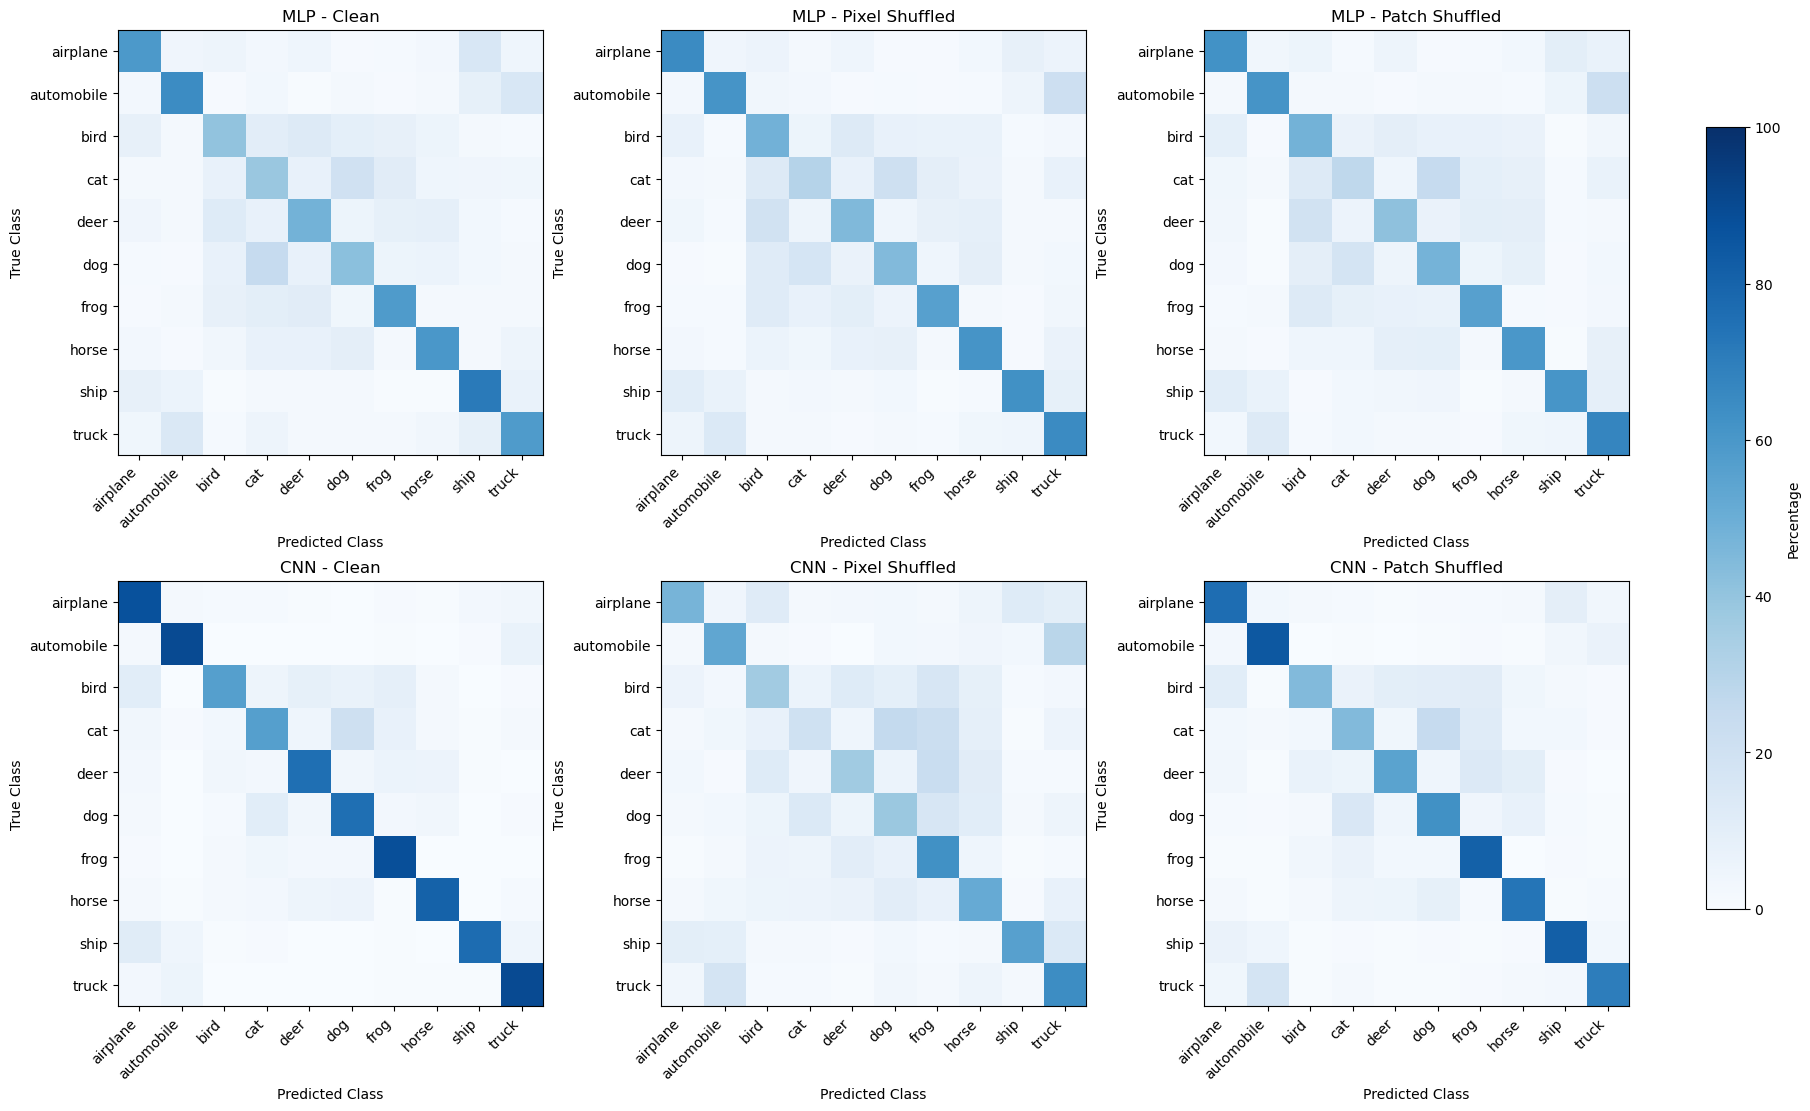

In [106]:
class_names = full_dataset.classes

conditions = [
    "Clean",
    "Pixel Shuffled",
    "Patch Shuffled"
]

fig, axes = plt.subplots(
    2, 3, figsize=(18, 11),
    constrained_layout=True
)

for i, model_name in enumerate(["MLP", "CNN"]):

    for j, condition in enumerate(conditions):

        cm = confusion_matrices[
            (model_name, condition)
        ]

        cm_percent = cm / cm.sum(
            axis=1, keepdims=True
        ) * 100

        ax = axes[i, j]

        im = ax.imshow(
            cm_percent,
            cmap="Blues",
            vmin=0,
            vmax=100
        )

        ax.set_title(f"{model_name} - {condition}")

        ax.set_xticks(range(10))
        ax.set_yticks(range(10))

        ax.set_xticklabels(
            class_names, rotation=45, ha="right"
        )

        ax.set_yticklabels(class_names)

        ax.set_xlabel("Predicted Class")
        ax.set_ylabel("True Class")

fig.colorbar(im, ax=axes, shrink=0.8, label="Percentage")

plt.savefig(
    "figures/q2_confusion_matrices.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [107]:
error_summary = []

for condition in conditions:

    cm = confusion_matrices[("CNN", condition)]

    errors = cm.copy()

    np.fill_diagonal(errors, 0)

    top_errors = np.argsort(
        errors.flatten()
    )[-3:][::-1]

    for index in top_errors:

        actual, predicted = np.unravel_index(
            index, errors.shape
        )

        error_summary.append({
            "Condition": condition,
            "True Class": class_names[actual],
            "Predicted Class": class_names[predicted],
            "Number of Errors": errors[actual, predicted]
        })

error_summary_df = pd.DataFrame(error_summary)

display(error_summary_df)

error_summary_df.to_csv(
    "results/q2_cnn_error_analysis.csv",
    index=False
)

,Condition,True Class,Predicted Class,Number of Errors
0,Clean,cat,dog,207
1,Clean,ship,airplane,116
2,Clean,dog,cat,109
3,Pixel Shuffled,automobile,truck,286
4,Pixel Shuffled,cat,dog,255
5,Pixel Shuffled,deer,frog,232
6,Patch Shuffled,cat,dog,248
7,Patch Shuffled,truck,automobile,176
8,Patch Shuffled,dog,cat,150


In [108]:
q2_accuracy_table = final_q2_df.pivot(
    index=["Model", "Parameters"],
    columns="Condition",
    values="Test Accuracy (%)"
)

q2_accuracy_table = q2_accuracy_table[
    ["Clean", "Pixel Shuffled", "Patch Shuffled"]
]

display(q2_accuracy_table.round(2))

q2_accuracy_table.to_csv(
    "results/q2_final_accuracy_table.csv"
)

,Condition,Clean,Pixel Shuffled,Patch Shuffled
Model,Parameters,,,
CNN,963466,77.65,46.49,67.33
MLP,1052426,54.03,53.82,53.04


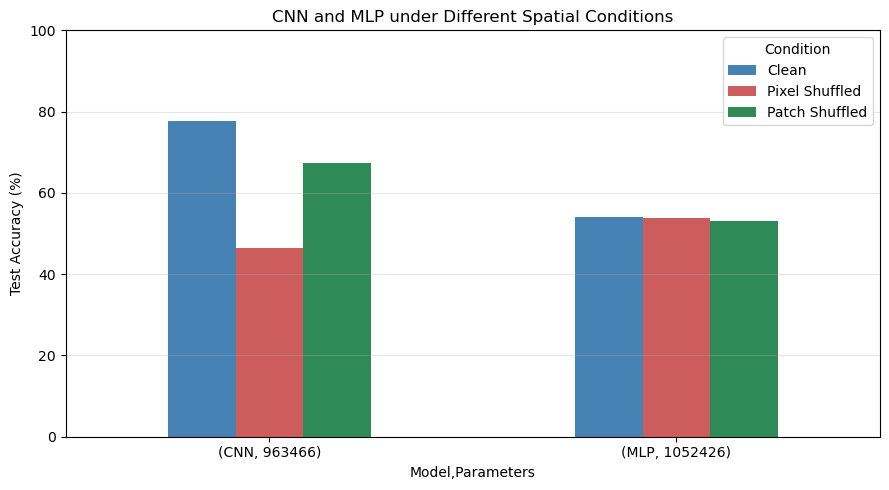

In [109]:
q2_accuracy_table.plot(
    kind="bar",
    figsize=(9, 5),
    color=["steelblue", "indianred", "seagreen"]
)

plt.ylabel("Test Accuracy (%)")
plt.title("CNN and MLP under Different Spatial Conditions")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("figures/q2_final_comparison.png", dpi=300)
plt.show()

# Q3(a) - Convolutional Autoencoders

Three convolutional autoencoders with bottleneck sizes
of 32, 128 and 512 are trained under the same training setup.

The best autoencoder is selected using the lowest
validation reconstruction error.

In [110]:
class Autoencoder(nn.Module):

    def __init__(self, latent_dim):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Conv2d(3, 32, 4, stride=2, padding=1),
            nn.ReLU(),

            nn.Conv2d(32, 64, 4, stride=2, padding=1),
            nn.ReLU(),

            nn.Conv2d(64, 128, 4, stride=2, padding=1),
            nn.ReLU(),

            nn.Flatten(),

            nn.Linear(128 * 4 * 4, latent_dim)
        )

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 128 * 4 * 4),
            nn.ReLU(),

            nn.Unflatten(1, (128, 4, 4)),

            nn.ConvTranspose2d(128, 64, 4, stride=2, padding=1),
            nn.ReLU(),

            nn.ConvTranspose2d(64, 32, 4, stride=2, padding=1),
            nn.ReLU(),

            nn.ConvTranspose2d(32, 3, 4, stride=2, padding=1),
            nn.Tanh()
        )

    def forward(self, x):

        z = self.encoder(x)

        reconstructed = self.decoder(z)

        return reconstructed

In [111]:
latent_sizes = [32, 128, 512]

epochs_ae = 30
lr_ae = 0.001

criterion_ae = nn.MSELoss()

In [112]:
config_ae = {
    "seed": seed,
    "bottleneck_sizes": latent_sizes,
    "encoder_channels": [3, 32, 64, 128],
    "kernel_size": 4,
    "stride": 2,
    "padding": 1,
    "epochs": epochs_ae,
    "batch_size": batch_size,
    "optimizer": "Adam",
    "learning_rate": lr_ae,
    "loss": "MSELoss",
    "pixel_range": [-1, 1],
    "checkpoint_selection": "Lowest validation MSE"
}

with open("results/q3a_config.json", "w") as f:
    json.dump(config_ae, f, indent=4)

In [113]:
def evaluate_ae(model, loader):

    model.eval()

    total_loss = 0
    total = 0

    with torch.no_grad():

        for images, _ in loader:

            images = images.to(device)

            reconstructed = model(images)

            loss = criterion_ae(reconstructed, images)

            total_loss += loss.item() * images.size(0)

            total += images.size(0)

    return total_loss / total

In [114]:
def train_autoencoder(model, name):

    optimizer = optim.Adam(
        model.parameters(), lr=lr_ae
    )

    train_loader_ae = get_train_loader()

    history = []

    best_val_loss = float("inf")

    start_time = time.time()

    for epoch in range(epochs_ae):

        model.train()

        total_loss = 0
        total = 0

        for images, _ in train_loader_ae:

            images = images.to(device)

            optimizer.zero_grad()

            reconstructed = model(images)

            loss = criterion_ae(reconstructed, images)

            loss.backward()

            optimizer.step()

            total_loss += loss.item() * images.size(0)

            total += images.size(0)

        train_loss = total_loss / total

        val_loss = evaluate_ae(model, val_loader)

        history.append({
            "epoch": epoch + 1,
            "train_loss": train_loss,
            "val_loss": val_loss
        })

        if val_loss < best_val_loss:

            best_val_loss = val_loss

            torch.save(
                model.state_dict(),
                f"checkpoints/{name}.pth"
            )

        print(
            f"Epoch {epoch+1}/{epochs_ae} | "
            f"Train MSE: {train_loss:.6f} | "
            f"Val MSE: {val_loss:.6f}"
        )

    elapsed = time.time() - start_time

    history = pd.DataFrame(history)

    history.to_csv(
        f"results/{name}_history.csv",
        index=False
    )

    model.load_state_dict(
        torch.load(
            f"checkpoints/{name}.pth",
            map_location=device
        )
    )

    print("Best validation MSE:", best_val_loss)
    print("Training time:", round(elapsed, 2), "seconds")

    return history, elapsed

In [115]:
ae_models = {}
ae_histories = {}
ae_times = {}

for latent_dim in latent_sizes:

    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    model = Autoencoder(latent_dim).to(device)

    print("\nTraining Autoencoder:", latent_dim)
    print("Parameters:", count_parameters(model))

    history, elapsed = train_autoencoder(
        model,
        f"q3a_ae_{latent_dim}"
    )

    ae_models[latent_dim] = model

    ae_histories[latent_dim] = history

    ae_times[latent_dim] = elapsed


Training Autoencoder: 32
Parameters: 464227
Epoch 1/30 | Train MSE: 0.099165 | Val MSE: 0.059716
Epoch 2/30 | Train MSE: 0.054713 | Val MSE: 0.051123
Epoch 3/30 | Train MSE: 0.050667 | Val MSE: 0.049767
Epoch 4/30 | Train MSE: 0.049408 | Val MSE: 0.048715
Epoch 5/30 | Train MSE: 0.048455 | Val MSE: 0.048212
Epoch 6/30 | Train MSE: 0.047728 | Val MSE: 0.047398
Epoch 7/30 | Train MSE: 0.047261 | Val MSE: 0.047313
Epoch 8/30 | Train MSE: 0.046924 | Val MSE: 0.046970
Epoch 9/30 | Train MSE: 0.046567 | Val MSE: 0.046912
Epoch 10/30 | Train MSE: 0.046352 | Val MSE: 0.046542
Epoch 11/30 | Train MSE: 0.046092 | Val MSE: 0.046617
Epoch 12/30 | Train MSE: 0.045924 | Val MSE: 0.046305
Epoch 13/30 | Train MSE: 0.045690 | Val MSE: 0.046292
Epoch 14/30 | Train MSE: 0.045532 | Val MSE: 0.046257
Epoch 15/30 | Train MSE: 0.045348 | Val MSE: 0.046007
Epoch 16/30 | Train MSE: 0.045222 | Val MSE: 0.046120
Epoch 17/30 | Train MSE: 0.045080 | Val MSE: 0.045801
Epoch 18/30 | Train MSE: 0.044923 | Val MSE: 0

In [116]:
ae_results = []

for latent_dim in latent_sizes:

    history = ae_histories[latent_dim]

    best_row = history.loc[
        history["val_loss"].idxmin()
    ]

    ae_results.append({
        "Bottleneck": latent_dim,
        "Parameters": count_parameters(ae_models[latent_dim]),
        "Best Epoch": int(best_row["epoch"]),
        "Training MSE": best_row["train_loss"],
        "Validation MSE": best_row["val_loss"],
        "Training Time (s)": ae_times[latent_dim]
    })

ae_results_df = pd.DataFrame(ae_results)

display(ae_results_df.round(6))

ae_results_df.to_csv(
    "results/q3a_comparison.csv",
    index=False
)

,Bottleneck,Parameters,Best Epoch,Training MSE,Validation MSE,Training Time (s)
0,32,464227,27,0.044045,0.045630,135.225229
1,128,857539,30,0.017938,0.018372,134.548289
2,512,2430787,29,0.007158,0.006910,144.281907


In [117]:
best_ae_row = ae_results_df.loc[
    ae_results_df["Validation MSE"].idxmin()
]

best_latent = int(best_ae_row["Bottleneck"])

best_autoencoder = ae_models[best_latent]

print("Selected bottleneck:", best_latent)
print("Parameters:", count_parameters(best_autoencoder))
print("Best validation MSE:", best_ae_row["Validation MSE"])

Selected bottleneck: 512
Parameters: 2430787
Best validation MSE: 0.006910235050320625


In [118]:
ae_test_mse = evaluate_ae(
    best_autoencoder, test_loader
)

print("Selected bottleneck:", best_latent)

print("Test reconstruction MSE:", round(ae_test_mse, 6))

pd.DataFrame([{
    "Bottleneck": best_latent,
    "Parameters": count_parameters(best_autoencoder),
    "Validation MSE": best_ae_row["Validation MSE"],
    "Test MSE": ae_test_mse
}]).to_csv(
    "results/q3a_test_results.csv",
    index=False
)

Selected bottleneck: 512
Test reconstruction MSE: 0.006949


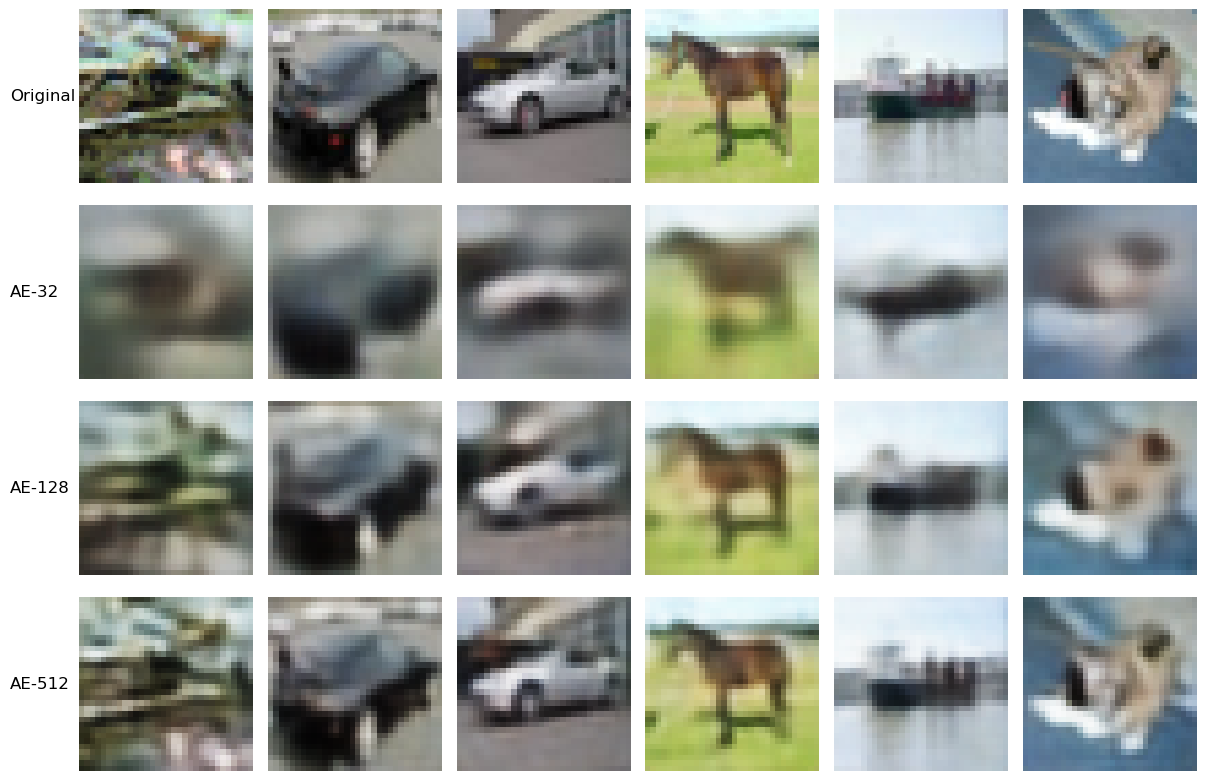

In [119]:
images, _ = next(iter(val_loader))
images = images[:6].to(device)

fig, axes = plt.subplots(4, 6, figsize=(12, 8))

# Original images
for i in range(6):

    image = images[i].cpu() * 0.5 + 0.5

    axes[0, i].imshow(image.permute(1, 2, 0).numpy())
    axes[0, i].axis("off")

axes[0, 0].set_ylabel("Original")

# Reconstructed images
for row, latent_dim in enumerate(latent_sizes, start=1):

    model = ae_models[latent_dim]
    model.eval()

    with torch.no_grad():
        reconstructed = model(images).cpu()

    for i in range(6):

        image = reconstructed[i] * 0.5 + 0.5

        axes[row, i].imshow(image.permute(1, 2, 0).numpy())
        axes[row, i].axis("off")

    axes[row, 0].text(
        -0.4, 0.5, f"AE-{latent_dim}",
        transform=axes[row, 0].transAxes,
        fontsize=12, va="center"
    )

axes[0, 0].text(
    -0.4, 0.5, "Original",
    transform=axes[0, 0].transAxes,
    fontsize=12, va="center"
)

plt.tight_layout()
plt.savefig("figures/q3a_reconstructions.png", dpi=300,
            bbox_inches="tight")
plt.show()

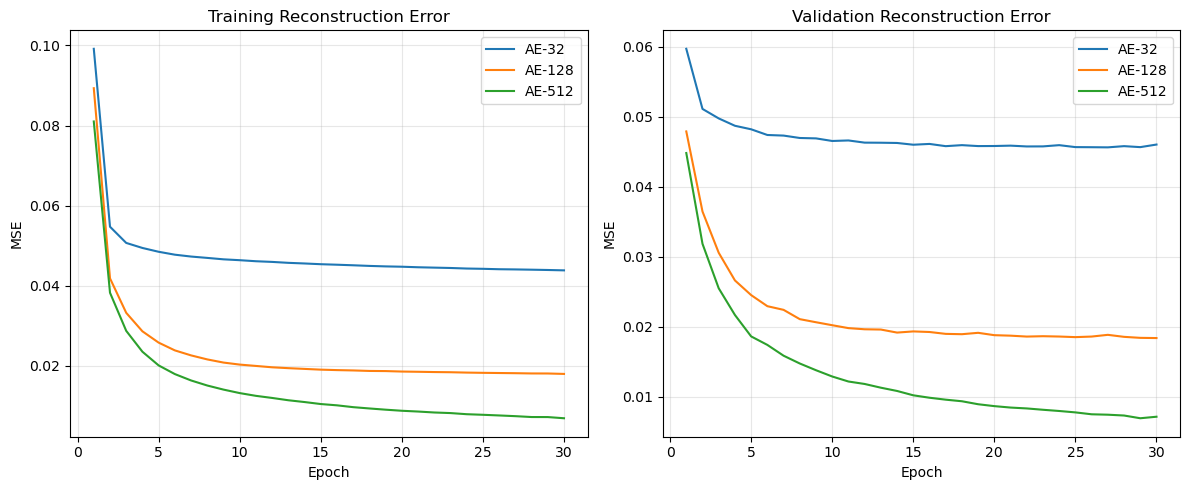

In [120]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for latent_dim in latent_sizes:

    history = ae_histories[latent_dim]

    axes[0].plot(
        history["epoch"],
        history["train_loss"],
        label=f"AE-{latent_dim}"
    )

    axes[1].plot(
        history["epoch"],
        history["val_loss"],
        label=f"AE-{latent_dim}"
    )

axes[0].set_title("Training Reconstruction Error")
axes[1].set_title("Validation Reconstruction Error")

for ax in axes:

    ax.set_xlabel("Epoch")
    ax.set_ylabel("MSE")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("figures/q3a_loss_curves.png", dpi=300)
plt.show()

# Q3(b) - Denoising Autoencoder

Gaussian noise is added to CIFAR10 images.

A denoising autoencoder is trained using corrupted images
as inputs and their corresponding clean images as targets.

A fixed CNN classifier is used to investigate whether
denoising recovers useful class information.

In [121]:
noise_sigma = 0.4

def add_noise(images, generator):

    noise = torch.randn(
        images.shape,
        generator=generator,
        dtype=images.dtype
    )

    noisy_images = images + noise_sigma * noise

    noisy_images = torch.clamp(noisy_images, -1, 1)

    return noisy_images

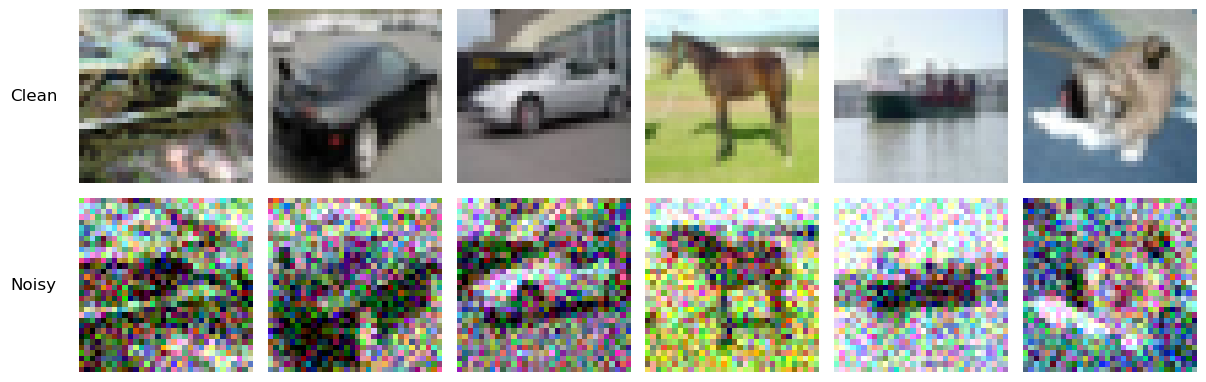

In [122]:
noise_train_seed = seed + 1
noise_val_seed = seed + 2
noise_test_seed = seed + 3

generator_noise = torch.Generator()
generator_noise.manual_seed(noise_val_seed)

images, _ = next(iter(val_loader))

images = images[:6]

noisy_images = add_noise(images, generator_noise)

fig, axes = plt.subplots(2, 6, figsize=(12, 4))

for i in range(6):

    original = images[i] * 0.5 + 0.5

    corrupted = noisy_images[i] * 0.5 + 0.5

    axes[0, i].imshow(original.permute(1, 2, 0).numpy())
    axes[1, i].imshow(corrupted.permute(1, 2, 0).numpy())

    axes[0, i].axis("off")
    axes[1, i].axis("off")

axes[0, 0].text(
    -0.4, 0.5, "Clean",
    transform=axes[0, 0].transAxes,
    fontsize=12, va="center"
)

axes[1, 0].text(
    -0.4, 0.5, "Noisy",
    transform=axes[1, 0].transAxes,
    fontsize=12, va="center"
)

plt.tight_layout()
plt.savefig("figures/q3b_noisy_images.png", dpi=300,
            bbox_inches="tight")
plt.show()

In [123]:
torch.manual_seed(seed)
torch.cuda.manual_seed_all(seed)

model_dae = Autoencoder(best_latent).to(device)

optimizer_dae = optim.Adam(
    model_dae.parameters(),
    lr=0.001
)

epochs_dae = 30

print("Bottleneck size:", best_latent)
print("Parameters:", count_parameters(model_dae))

Bottleneck size: 512
Parameters: 2430787


In [124]:
fixed_cnn = copy.deepcopy(model_cnn_best)

fixed_cnn.eval()

for param in fixed_cnn.parameters():
    param.requires_grad = False

best_autoencoder.eval()

print("Fixed CNN is ready")

Fixed CNN is ready


In [125]:
config_dae = {
    "seed": seed,
    "bottleneck": best_latent,
    "parameters": count_parameters(model_dae),
    "corruption": "Gaussian noise",
    "noise_std": noise_sigma,
    "pixel_range": [-1, 1],
    "noise_train_seed": noise_train_seed,
    "noise_val_seed": noise_val_seed,
    "noise_test_seed": noise_test_seed,
    "epochs": epochs_dae,
    "batch_size": batch_size,
    "optimizer": "Adam",
    "learning_rate": 0.001,
    "loss": "MSELoss",
    "clean_ae_baseline": "q3a_ae_512.pth",
    "fixed_classifier": "cnn_best.pth",
    "checkpoint_selection": "Lowest validation MSE"
}

with open("results/q3b_config.json", "w") as f:
    json.dump(config_dae, f, indent=4)

In [126]:
config_dae = {
    "seed": seed,
    "bottleneck": best_latent,
    "parameters": count_parameters(model_dae),
    "corruption": "Gaussian noise",
    "noise_std": noise_sigma,
    "pixel_range": [-1, 1],
    "noise_train_seed": noise_train_seed,
    "noise_val_seed": noise_val_seed,
    "noise_test_seed": noise_test_seed,
    "epochs": epochs_dae,
    "batch_size": batch_size,
    "optimizer": "Adam",
    "learning_rate": 0.001,
    "loss": "MSELoss",
    "clean_ae_baseline": "q3a_ae_512.pth",
    "fixed_classifier": "cnn_best.pth",
    "checkpoint_selection": "Lowest validation MSE"
}

with open("results/q3b_config.json", "w") as f:
    json.dump(config_dae, f, indent=4)

In [128]:
def evaluate_dae(model, loader, noise_seed):

    model.eval()

    generator = torch.Generator()
    generator.manual_seed(noise_seed)

    total_loss = 0
    total = 0

    with torch.no_grad():

        for images, _ in loader:

            noisy_images = add_noise(images, generator)

            images = images.to(device)
            noisy_images = noisy_images.to(device)

            reconstructed = model(noisy_images)

            loss = criterion_ae(reconstructed, images)

            total_loss += loss.item() * images.size(0)

            total += images.size(0)

    return total_loss / total

In [129]:
train_loader_dae = get_train_loader()

generator_dae = torch.Generator()
generator_dae.manual_seed(noise_train_seed)

history_dae = []

best_dae_val_loss = float("inf")
best_dae_epoch = 0

start_time = time.time()

for epoch in range(epochs_dae):

    model_dae.train()

    total_loss = 0
    total = 0

    for images, _ in train_loader_dae:

        noisy_images = add_noise(images, generator_dae)

        images = images.to(device)
        noisy_images = noisy_images.to(device)

        optimizer_dae.zero_grad()

        reconstructed = model_dae(noisy_images)

        loss = criterion_ae(reconstructed, images)

        loss.backward()

        optimizer_dae.step()

        total_loss += loss.item() * images.size(0)

        total += images.size(0)

    train_loss = total_loss / total

    val_loss = evaluate_dae(
        model_dae, val_loader, noise_val_seed
    )

    history_dae.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "val_loss": val_loss
    })

    if val_loss < best_dae_val_loss:

        best_dae_val_loss = val_loss
        best_dae_epoch = epoch + 1

        torch.save(
            model_dae.state_dict(),
            "checkpoints/q3b_dae.pth"
        )

    print(
        f"Epoch {epoch+1}/{epochs_dae} | "
        f"Train MSE: {train_loss:.6f} | "
        f"Val MSE: {val_loss:.6f}"
    )

print("Best validation MSE:", best_dae_val_loss)
print("Best epoch:", best_dae_epoch)
print("Training time:", round(time.time() - start_time, 2))

Epoch 1/30 | Train MSE: 0.043621 | Val MSE: 0.039980
Epoch 2/30 | Train MSE: 0.035386 | Val MSE: 0.032617
Epoch 3/30 | Train MSE: 0.030724 | Val MSE: 0.029426
Epoch 4/30 | Train MSE: 0.027943 | Val MSE: 0.026969
Epoch 5/30 | Train MSE: 0.026049 | Val MSE: 0.025638
Epoch 6/30 | Train MSE: 0.024771 | Val MSE: 0.024296
Epoch 7/30 | Train MSE: 0.023664 | Val MSE: 0.023368
Epoch 8/30 | Train MSE: 0.022866 | Val MSE: 0.022763
Epoch 9/30 | Train MSE: 0.022238 | Val MSE: 0.022464
Epoch 10/30 | Train MSE: 0.021672 | Val MSE: 0.022339
Epoch 11/30 | Train MSE: 0.021206 | Val MSE: 0.022248
Epoch 12/30 | Train MSE: 0.020790 | Val MSE: 0.020860
Epoch 13/30 | Train MSE: 0.020451 | Val MSE: 0.020566
Epoch 14/30 | Train MSE: 0.020112 | Val MSE: 0.020560
Epoch 15/30 | Train MSE: 0.019884 | Val MSE: 0.019927
Epoch 16/30 | Train MSE: 0.019540 | Val MSE: 0.019745
Epoch 17/30 | Train MSE: 0.019358 | Val MSE: 0.019548
Epoch 18/30 | Train MSE: 0.019232 | Val MSE: 0.019246
Epoch 19/30 | Train MSE: 0.018981 | V

In [130]:
model_dae.load_state_dict(
    torch.load(
        "checkpoints/q3b_dae.pth",
        map_location=device
    )
)

history_dae_df = pd.DataFrame(history_dae)

history_dae_df.to_csv(
    "results/q3b_history.csv",
    index=False
)

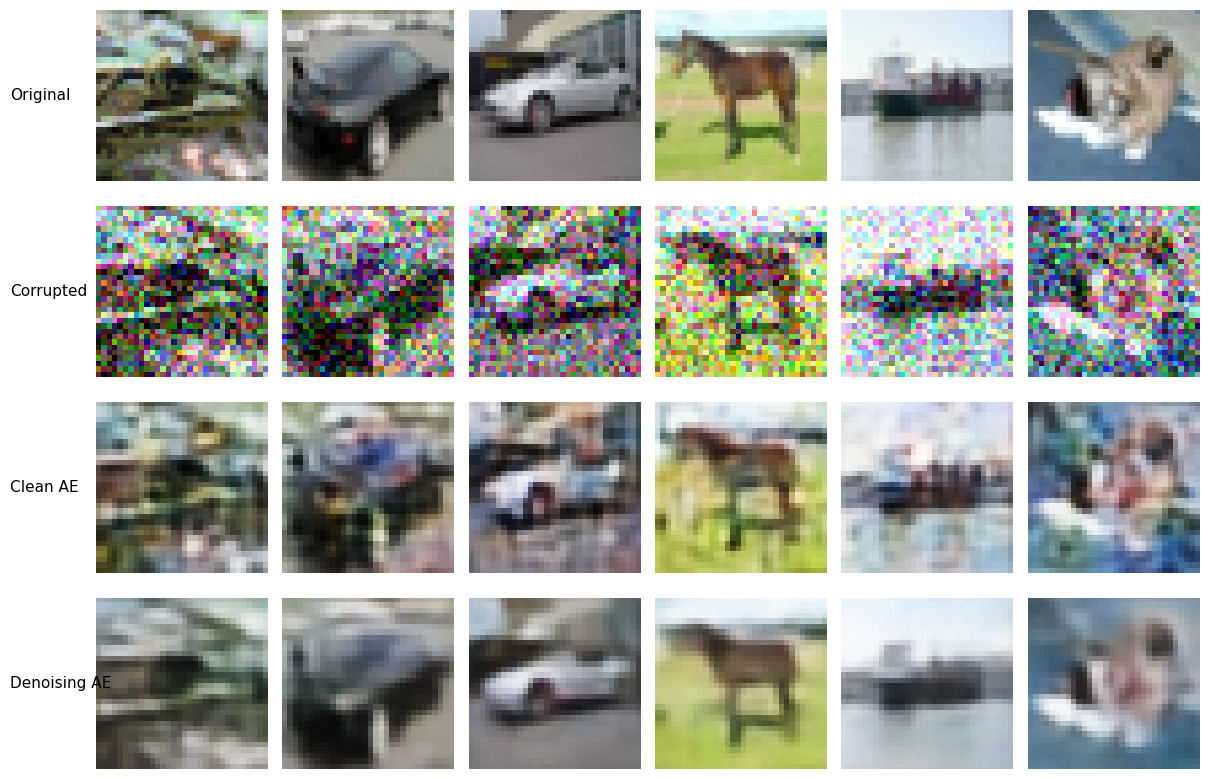

In [131]:
generator_visual = torch.Generator()
generator_visual.manual_seed(noise_val_seed)

images, _ = next(iter(val_loader))

images = images[:6]

noisy_images = add_noise(images, generator_visual)

best_autoencoder.eval()
model_dae.eval()

with torch.no_grad():

    clean_ae_output = best_autoencoder(
        noisy_images.to(device)
    ).cpu()

    dae_output = model_dae(
        noisy_images.to(device)
    ).cpu()

image_rows = [
    images,
    noisy_images,
    clean_ae_output,
    dae_output
]

row_names = [
    "Original",
    "Corrupted",
    "Clean AE",
    "Denoising AE"
]

fig, axes = plt.subplots(4, 6, figsize=(12, 8))

for row in range(4):

    for i in range(6):

        image = image_rows[row][i] * 0.5 + 0.5

        axes[row, i].imshow(
            image.permute(1, 2, 0).numpy()
        )

        axes[row, i].axis("off")

    axes[row, 0].text(
        -0.5, 0.5, row_names[row],
        transform=axes[row, 0].transAxes,
        fontsize=11, va="center"
    )

plt.tight_layout()

plt.savefig(
    "figures/q3b_denoising_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

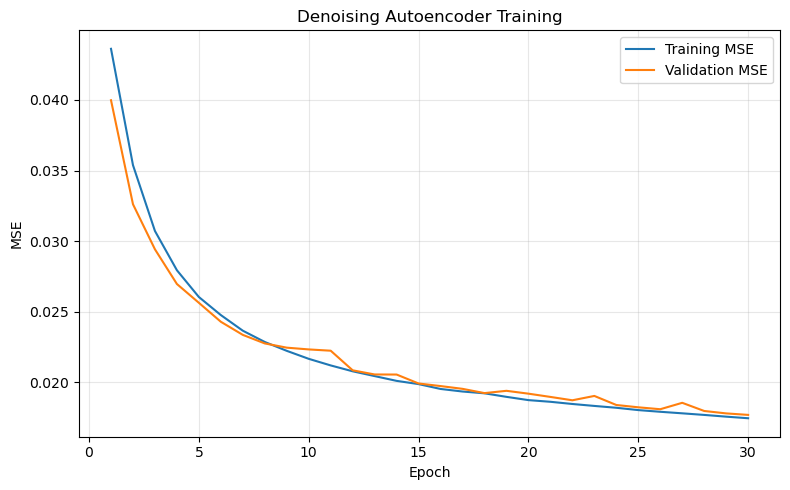

In [132]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_dae_df["epoch"],
    history_dae_df["train_loss"],
    label="Training MSE"
)

plt.plot(
    history_dae_df["epoch"],
    history_dae_df["val_loss"],
    label="Validation MSE"
)

plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Denoising Autoencoder Training")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("figures/q3b_loss_curves.png", dpi=300)
plt.show()

In [133]:
generator_test = torch.Generator()
generator_test.manual_seed(noise_test_seed)

input_types = [
    "Clean",
    "Corrupted",
    "Clean AE",
    "Denoising AE"
]

correct_counts = {
    name: 0 for name in input_types
}

mse_totals = {
    name: 0 for name in input_types
}

total = 0

fixed_cnn.eval()
best_autoencoder.eval()
model_dae.eval()

with torch.no_grad():

    for images, labels in test_loader:

        noisy_images = add_noise(images, generator_test)

        images = images.to(device)
        labels = labels.to(device)
        noisy_images = noisy_images.to(device)

        clean_ae_rec = best_autoencoder(noisy_images)

        dae_rec = model_dae(noisy_images)

        inputs = {
            "Clean": images,
            "Corrupted": noisy_images,
            "Clean AE": clean_ae_rec,
            "Denoising AE": dae_rec
        }

        for name, input_images in inputs.items():

            outputs = fixed_cnn(input_images)

            predictions = outputs.argmax(dim=1)

            correct_counts[name] += (
                predictions == labels
            ).sum().item()

            mse = criterion_ae(input_images, images)

            mse_totals[name] += mse.item() * images.size(0)

        total += labels.size(0)

In [134]:
q3b_results = []

for name in input_types:

    q3b_results.append({
        "Input": name,
        "Test MSE": mse_totals[name] / total,
        "Test Accuracy (%)": 100 * correct_counts[name] / total
    })

q3b_results_df = pd.DataFrame(q3b_results)

display(q3b_results_df.round(6))

q3b_results_df.to_csv(
    "results/q3b_final_results.csv",
    index=False
)

,Input,Test MSE,Test Accuracy (%)
0,Clean,0.000000,81.41
1,Corrupted,0.133201,30.90
2,Clean AE,0.028903,48.04
3,Denoising AE,0.017732,53.18


In [135]:
acc_corrupted = q3b_results_df.loc[
    q3b_results_df["Input"] == "Corrupted",
    "Test Accuracy (%)"
].iloc[0]

acc_dae = q3b_results_df.loc[
    q3b_results_df["Input"] == "Denoising AE",
    "Test Accuracy (%)"
].iloc[0]

improvement = acc_dae - acc_corrupted

print(
    "Classification improvement after denoising:",
    round(improvement, 2),
    "percentage points"
)

Classification improvement after denoising: 22.28 percentage points


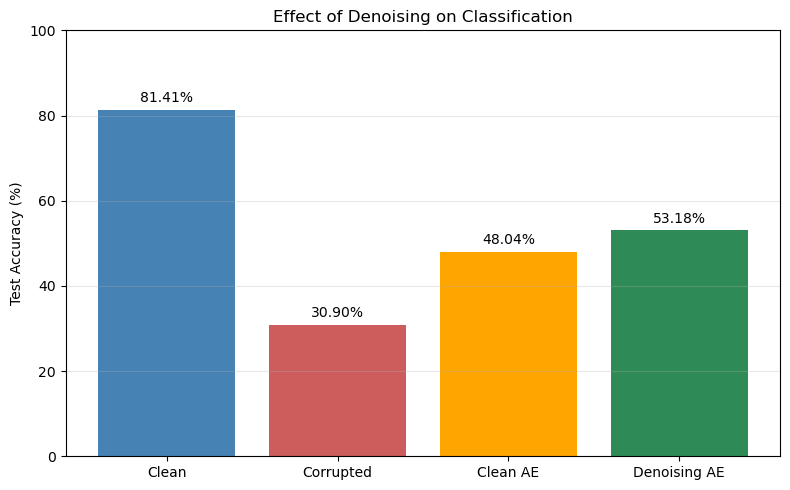

In [136]:
plt.figure(figsize=(8, 5))

bars = plt.bar(
    q3b_results_df["Input"],
    q3b_results_df["Test Accuracy (%)"],
    color=["steelblue", "indianred", "orange", "seagreen"]
)

plt.bar_label(bars, fmt="%.2f%%", padding=3)

plt.ylabel("Test Accuracy (%)")
plt.title("Effect of Denoising on Classification")
plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("figures/q3b_classification_comparison.png", dpi=300)
plt.show()

# Q3(c) - Class Information in Learned Representations

The encoders trained in Q3(a) are frozen.

Linear classifiers are trained on the bottleneck representations
of each autoencoder.

Classification accuracy is compared with reconstruction MSE
to investigate whether better reconstruction also results
in better class representations.

In [137]:
encoders = {}

for latent_dim in latent_sizes:

    encoder = copy.deepcopy(
        ae_models[latent_dim].encoder
    )

    encoder.eval()

    for param in encoder.parameters():
        param.requires_grad = False

    encoders[latent_dim] = encoder

    print(
        f"Encoder-{latent_dim} frozen:",
        not any(p.requires_grad for p in encoder.parameters())
    )

Encoder-32 frozen: True
Encoder-128 frozen: True
Encoder-512 frozen: True


In [138]:
def extract_features(encoder, loader):

    encoder.eval()

    all_features = []
    all_labels = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)

            features = encoder(images)

            all_features.append(features.cpu())
            all_labels.append(labels)

    features = torch.cat(all_features, dim=0)
    labels = torch.cat(all_labels, dim=0)

    return features, labels

In [139]:
feature_train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=False
)

ae_features = {}

for latent_dim in latent_sizes:

    X_train, y_train = extract_features(
        encoders[latent_dim], feature_train_loader
    )

    X_val, y_val = extract_features(
        encoders[latent_dim], val_loader
    )

    ae_features[latent_dim] = {
        "X_train": X_train,
        "y_train": y_train,
        "X_val": X_val,
        "y_val": y_val
    }

    print(f"\nBottleneck: {latent_dim}")
    print("Training features:", X_train.shape)
    print("Validation features:", X_val.shape)


Bottleneck: 32
Training features: torch.Size([45000, 32])
Validation features: torch.Size([5000, 32])

Bottleneck: 128
Training features: torch.Size([45000, 128])
Validation features: torch.Size([5000, 128])

Bottleneck: 512
Training features: torch.Size([45000, 512])
Validation features: torch.Size([5000, 512])


In [140]:
for latent_dim in latent_sizes:

    data = ae_features[latent_dim]

    mean = data["X_train"].mean(dim=0)

    std = data["X_train"].std(
        dim=0, unbiased=False
    ).clamp_min(1e-6)

    data["X_train"] = (data["X_train"] - mean) / std

    data["X_val"] = (data["X_val"] - mean) / std

    data["mean"] = mean
    data["std"] = std

    np.savez(
        f"results/q3c_scaler_{latent_dim}.npz",
        mean=mean.numpy(),
        std=std.numpy()
    )

In [141]:
from torch.utils.data import TensorDataset

config_probe = {
    "seed": seed,
    "bottleneck_sizes": latent_sizes,
    "encoder_frozen": True,
    "classifier": "Linear",
    "optimizer": "Adam",
    "learning_rate": 0.001,
    "epochs": 30,
    "batch_size": batch_size,
    "loss": "CrossEntropyLoss",
    "standardization": "Training features only",
    "checkpoint_selection": "Highest validation accuracy"
}

with open("results/q3c_config.json", "w") as f:
    json.dump(config_probe, f, indent=4)

In [142]:
probe_models = {}
probe_histories = {}
probe_times = {}

for latent_dim in latent_sizes:

    data = ae_features[latent_dim]

    probe_train = TensorDataset(
        data["X_train"], data["y_train"]
    )

    probe_val = TensorDataset(
        data["X_val"], data["y_val"]
    )

    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    probe = nn.Linear(latent_dim, 10).to(device)

    optimizer_probe = optim.Adam(
        probe.parameters(),
        lr=0.001
    )

    print(f"\nTraining linear probe for AE-{latent_dim}")

    print("Classifier parameters:", count_parameters(probe))

    history, elapsed = train_spatial_model(
        probe,
        optimizer_probe,
        f"q3c_probe_{latent_dim}",
        probe_train,
        probe_val
    )

    probe_models[latent_dim] = probe
    probe_histories[latent_dim] = history
    probe_times[latent_dim] = elapsed


Training linear probe for AE-32
Classifier parameters: 330
Epoch 1/30 | Train Loss: 2.0785 | Train Acc: 26.03% | Val Loss: 1.9233 | Val Acc: 33.06%
Epoch 2/30 | Train Loss: 1.8711 | Train Acc: 35.62% | Val Loss: 1.8553 | Val Acc: 35.54%
Epoch 3/30 | Train Loss: 1.8335 | Train Acc: 36.94% | Val Loss: 1.8364 | Val Acc: 36.18%
Epoch 4/30 | Train Loss: 1.8220 | Train Acc: 37.16% | Val Loss: 1.8295 | Val Acc: 35.90%
Epoch 5/30 | Train Loss: 1.8177 | Train Acc: 37.34% | Val Loss: 1.8262 | Val Acc: 36.42%
Epoch 6/30 | Train Loss: 1.8156 | Train Acc: 37.19% | Val Loss: 1.8245 | Val Acc: 36.00%
Epoch 7/30 | Train Loss: 1.8148 | Train Acc: 37.24% | Val Loss: 1.8235 | Val Acc: 36.28%
Epoch 8/30 | Train Loss: 1.8140 | Train Acc: 37.27% | Val Loss: 1.8247 | Val Acc: 36.06%
Epoch 9/30 | Train Loss: 1.8142 | Train Acc: 37.30% | Val Loss: 1.8229 | Val Acc: 36.38%
Epoch 10/30 | Train Loss: 1.8138 | Train Acc: 37.26% | Val Loss: 1.8222 | Val Acc: 36.26%
Epoch 11/30 | Train Loss: 1.8138 | Train Acc: 37.

In [143]:
probe_validation = []

for latent_dim in latent_sizes:

    probe_history = probe_histories[latent_dim]

    best_probe_row = probe_history.loc[
        probe_history["val_accuracy"].idxmax()
    ]

    reconstruction_error = ae_histories[latent_dim][
        "val_loss"
    ].min()

    probe_validation.append({
        "Bottleneck": latent_dim,
        "Validation MSE": reconstruction_error,
        "Best Probe Epoch": int(best_probe_row["epoch"]),
        "Validation Accuracy (%)": best_probe_row["val_accuracy"]
    })

probe_validation_df = pd.DataFrame(probe_validation)

display(probe_validation_df.round(6))

probe_validation_df.to_csv(
    "results/q3c_validation_results.csv",
    index=False
)

,Bottleneck,Validation MSE,Best Probe Epoch,Validation Accuracy (%)
0,32,0.045630,5,36.42
1,128,0.018372,27,39.90
2,512,0.006910,30,48.62


In [144]:
q3c_results = []

for latent_dim in latent_sizes:

    data = ae_features[latent_dim]

    X_test, y_test = extract_features(
        encoders[latent_dim], test_loader
    )

    X_test = (
        X_test - data["mean"]
    ) / data["std"]

    data["X_test"] = X_test
    data["y_test"] = y_test

    probe_test_dataset = TensorDataset(
        X_test, y_test
    )

    probe_test_loader = DataLoader(
        probe_test_dataset,
        batch_size=batch_size,
        shuffle=False
    )

    probe_test_loss, probe_test_acc = evaluate(
        probe_models[latent_dim],
        probe_test_loader
    )

    if latent_dim == best_latent:

        test_mse = ae_test_mse

    else:

        test_mse = evaluate_ae(
            ae_models[latent_dim], test_loader
        )

    q3c_results.append({
        "Bottleneck": latent_dim,
        "AE Parameters": count_parameters(ae_models[latent_dim]),
        "Classifier Parameters": count_parameters(probe_models[latent_dim]),
        "Test MSE": test_mse,
        "Test Accuracy (%)": probe_test_acc
    })

q3c_results_df = pd.DataFrame(q3c_results)

display(q3c_results_df.round(6))

q3c_results_df.to_csv(
    "results/q3c_final_results.csv",
    index=False
)

,Bottleneck,AE Parameters,Classifier Parameters,Test MSE,Test Accuracy (%)
0,32,464227,330,0.045806,37.27
1,128,857539,1290,0.018364,39.81
2,512,2430787,5130,0.006949,47.48


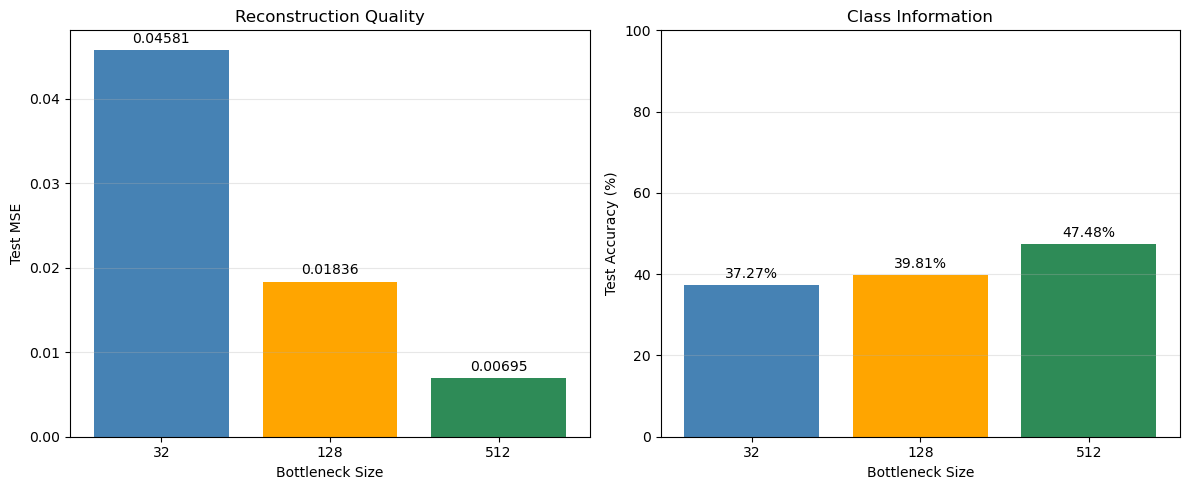

In [145]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sizes = q3c_results_df["Bottleneck"].astype(str)

# Reconstruction error

bars1 = axes[0].bar(
    sizes,
    q3c_results_df["Test MSE"],
    color=["steelblue", "orange", "seagreen"]
)

axes[0].bar_label(bars1, fmt="%.5f", padding=3)

axes[0].set_xlabel("Bottleneck Size")
axes[0].set_ylabel("Test MSE")
axes[0].set_title("Reconstruction Quality")

# Classification accuracy

bars2 = axes[1].bar(
    sizes,
    q3c_results_df["Test Accuracy (%)"],
    color=["steelblue", "orange", "seagreen"]
)

axes[1].bar_label(bars2, fmt="%.2f%%", padding=3)

axes[1].set_xlabel("Bottleneck Size")
axes[1].set_ylabel("Test Accuracy (%)")
axes[1].set_title("Class Information")
axes[1].set_ylim(0, 100)

for ax in axes:
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    "figures/q3c_reconstruction_vs_classification.png",
    dpi=300
)

plt.show()

In [146]:
best_reconstruction = q3c_results_df.loc[
    q3c_results_df["Test MSE"].idxmin()
]

best_classification = q3c_results_df.loc[
    q3c_results_df["Test Accuracy (%)"].idxmax()
]

print(
    "Lowest observed test MSE:",
    int(best_reconstruction["Bottleneck"])
)

print(
    "Highest observed test classification accuracy:",
    int(best_classification["Bottleneck"])
)

Lowest observed test MSE: 512
Highest observed test classification accuracy: 512


# Q4 - SVM and Clustering

A fixed autoencoder representation is selected using
validation linear-probe accuracy from Q3(c).

The same representation and fixed stratified training subset
are used for all SVM and clustering experiments.

In [147]:
from sklearn.svm import SVC
from sklearn.cluster import KMeans
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    silhouette_score,
    adjusted_rand_score,
    normalized_mutual_info_score
)

from itertools import combinations
import joblib

In [148]:
best_representation = int(
    probe_validation_df.loc[
        probe_validation_df["Validation Accuracy (%)"].idxmax(),
        "Bottleneck"
    ]
)

print("Selected representation:", best_representation)

representation = ae_features[best_representation]

X_q4_all = representation["X_train"].numpy()
y_q4_all = representation["y_train"].numpy()

X_q4_val = representation["X_val"].numpy()
y_q4_val = representation["y_val"].numpy()

Selected representation: 512


In [149]:
q4_rows, _ = train_test_split(
    np.arange(len(y_q4_all)),
    train_size=5000,
    stratify=y_q4_all,
    random_state=seed
)

X_q4_train = X_q4_all[q4_rows]
y_q4_train = y_q4_all[q4_rows]

q4_original_indices = train_indices[q4_rows]

np.savez(
    "results/q4_training_subset.npz",
    subset_rows=q4_rows,
    cifar10_indices=q4_original_indices,
    seed=seed
)

print("Training features:", X_q4_train.shape)
print("Validation features:", X_q4_val.shape)

print("Samples per training class:")
print(np.bincount(y_q4_train))

Training features: (5000, 512)
Validation features: (5000, 512)
Samples per training class:
[500 500 500 500 500 500 500 500 500 500]


## Q4(a) — SVM hyperparameter comparison

In [150]:
C_values = [0.001, 0.01, 0.1, 1, 10]

kernels = ["linear", "poly", "rbf"]

k_values = [5, 10, 15, 20]

config_q4 = {
    "seed": seed,
    "representation": f"AE-{best_representation}",
    "standardization": "Reused from Q3(c)",
    "training_subset_size": len(y_q4_train),
    "C_values": C_values,
    "kernels": kernels,
    "gamma": "scale",
    "polynomial_degree": 3,
    "polynomial_coef0": 1.0,
    "svm_selection": "Highest validation accuracy",
    "clustering_method": "KMeans",
    "cluster_candidates": k_values,
    "cluster_selection": "Highest validation silhouette score"
}

with open("results/q4_config.json", "w") as f:
    json.dump(config_q4, f, indent=4)

In [151]:
svm_results = []

best_svm = None
best_svm_val_acc = -1

for C in C_values:

    for kernel in kernels:

        start_time = time.time()

        svm = SVC(
            C=C,
            kernel=kernel,
            gamma="scale",
            degree=3,
            coef0=1.0,
            decision_function_shape="ovo",
            cache_size=500,
            random_state=seed
        )

        svm.fit(X_q4_train, y_q4_train)

        train_acc = svm.score(
            X_q4_train, y_q4_train
        ) * 100

        val_acc = svm.score(
            X_q4_val, y_q4_val
        ) * 100

        number_sv = len(svm.support_)

        sv_fraction = number_sv / len(y_q4_train)

        elapsed = time.time() - start_time

        svm_results.append({
            "Kernel": kernel,
            "C": C,
            "Training Accuracy (%)": train_acc,
            "Validation Accuracy (%)": val_acc,
            "Support Vectors": number_sv,
            "Support Vector Fraction": sv_fraction,
            "Training-Validation Gap (pp)": train_acc - val_acc,
            "Time (s)": elapsed
        })

        if val_acc > best_svm_val_acc:

            best_svm_val_acc = val_acc
            best_svm = svm

        print(
            f"Kernel: {kernel:6s} | "
            f"C: {C:7g} | "
            f"Train: {train_acc:.2f}% | "
            f"Val: {val_acc:.2f}% | "
            f"SV Fraction: {sv_fraction:.4f} | "
            f"Time: {elapsed:.1f}s"
        )

svm_sweep_df = pd.DataFrame(svm_results)

display(svm_sweep_df.round(4))

svm_sweep_df.to_csv(
    "results/q4a_svm_sweep.csv",
    index=False
)

Kernel: linear | C:   0.001 | Train: 53.66% | Val: 40.80% | SV Fraction: 0.9578 | Time: 19.4s
Kernel: poly   | C:   0.001 | Train: 32.24% | Val: 27.24% | SV Fraction: 1.0000 | Time: 22.9s
Kernel: rbf    | C:   0.001 | Train: 33.98% | Val: 28.40% | SV Fraction: 1.0000 | Time: 31.2s
Kernel: linear | C:    0.01 | Train: 67.84% | Val: 39.46% | SV Fraction: 0.9136 | Time: 16.8s
Kernel: poly   | C:    0.01 | Train: 45.16% | Val: 36.32% | SV Fraction: 0.9976 | Time: 21.7s
Kernel: rbf    | C:    0.01 | Train: 33.98% | Val: 28.40% | SV Fraction: 1.0000 | Time: 31.0s
Kernel: linear | C:     0.1 | Train: 84.08% | Val: 35.18% | SV Fraction: 0.8770 | Time: 18.8s
Kernel: poly   | C:     0.1 | Train: 75.70% | Val: 45.32% | SV Fraction: 0.9676 | Time: 19.2s
Kernel: rbf    | C:     0.1 | Train: 41.54% | Val: 34.54% | SV Fraction: 0.9992 | Time: 30.1s
Kernel: linear | C:       1 | Train: 95.12% | Val: 34.40% | SV Fraction: 0.8536 | Time: 30.8s
Kernel: poly   | C:       1 | Train: 97.92% | Val: 46.36% | 

,Kernel,C,Training Accuracy (%),Validation Accuracy (%),Support Vectors,Support Vector Fraction,Training-Validation Gap (pp),Time (s)
0,linear,0.001,53.66,40.80,4789,0.9578,12.86,19.3769
1,poly,0.001,32.24,27.24,5000,1.0000,5.00,22.9450
2,rbf,0.001,33.98,28.40,5000,1.0000,5.58,31.2141
3,linear,0.010,67.84,39.46,4568,0.9136,28.38,16.8298
4,poly,0.010,45.16,36.32,4988,0.9976,8.84,21.7298
5,rbf,0.010,33.98,28.40,5000,1.0000,5.58,31.0409
6,linear,0.100,84.08,35.18,4385,0.8770,48.90,18.8026
7,poly,0.100,75.70,45.32,4838,0.9676,30.38,19.1808
8,rbf,0.100,41.54,34.54,4996,0.9992,7.00,30.0817
9,linear,1.000,95.12,34.40,4268,0.8536,60.72,30.8142


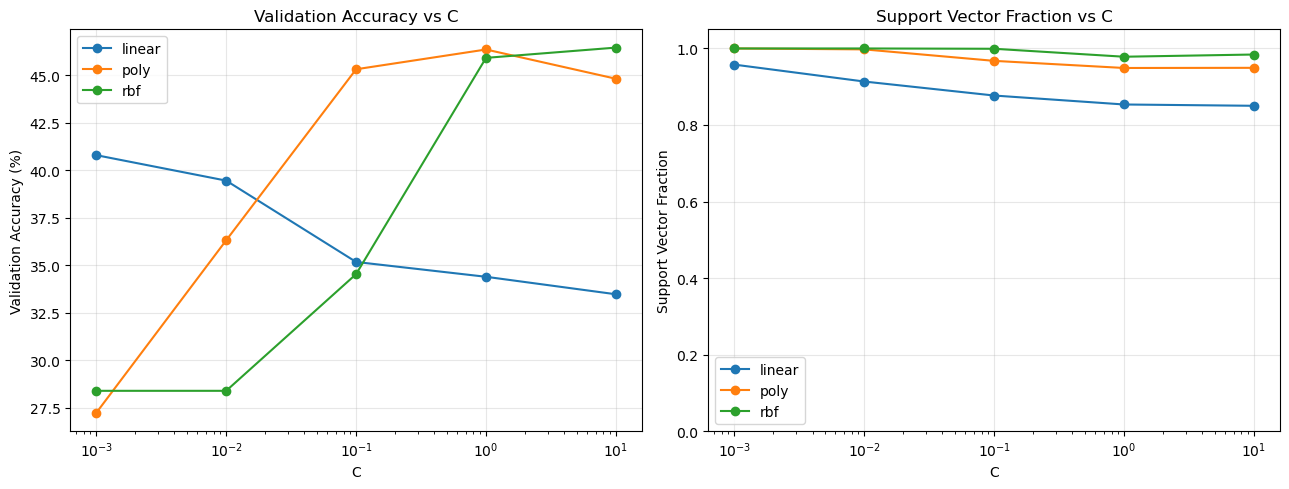

In [152]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for kernel in kernels:

    subset = svm_sweep_df[
        svm_sweep_df["Kernel"] == kernel
    ].sort_values("C")

    axes[0].semilogx(
        subset["C"],
        subset["Validation Accuracy (%)"],
        marker="o",
        label=kernel
    )

    axes[1].semilogx(
        subset["C"],
        subset["Support Vector Fraction"],
        marker="o",
        label=kernel
    )

axes[0].set_title("Validation Accuracy vs C")
axes[0].set_xlabel("C")
axes[0].set_ylabel("Validation Accuracy (%)")

axes[1].set_title("Support Vector Fraction vs C")
axes[1].set_xlabel("C")
axes[1].set_ylabel("Support Vector Fraction")
axes[1].set_ylim(0, 1.05)

for ax in axes:
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()

plt.savefig(
    "figures/q4a_svm_comparison.png",
    dpi=300
)

plt.show()

In [153]:
best_svm_row = svm_sweep_df.loc[
    svm_sweep_df["Validation Accuracy (%)"].idxmax()
]

display(best_svm_row)

print("Selected kernel:", best_svm.kernel)
print("Selected C:", best_svm.C)
print("Best validation accuracy:", best_svm_val_acc)

joblib.dump(
    best_svm,
    "checkpoints/q4a_best_svm.joblib"
)

Kernel                                rbf
C                                    10.0
Training Accuracy (%)               99.92
Validation Accuracy (%)             46.46
Support Vectors                      4921
Support Vector Fraction            0.9842
Training-Validation Gap (pp)        53.46
Time (s)                        31.852839
Name: 14, dtype: object

Selected kernel: rbf
Selected C: 10
Best validation accuracy: 46.46


['checkpoints/q4a_best_svm.joblib']

In [154]:
cluster_results = []

best_kmeans = None
best_silhouette = -np.inf
best_k = None

rng_cluster = np.random.default_rng(seed)

silhouette_rows = rng_cluster.choice(
    len(X_q4_val),
    size=2000,
    replace=False
)

for k in k_values:

    kmeans = KMeans(
        n_clusters=k,
        n_init=10,
        max_iter=300,
        random_state=seed
    )

    kmeans.fit(X_q4_train)

    val_clusters = kmeans.predict(X_q4_val)

    score = silhouette_score(
        X_q4_val[silhouette_rows],
        val_clusters[silhouette_rows]
    )

    cluster_results.append({
        "K": k,
        "Training Inertia": kmeans.inertia_,
        "Validation Silhouette Score": score
    })

    if score > best_silhouette:

        best_silhouette = score
        best_k = k
        best_kmeans = kmeans

    print(
        f"K: {k} | "
        f"Validation silhouette: {score:.4f}"
    )

cluster_sweep_df = pd.DataFrame(cluster_results)

display(cluster_sweep_df.round(4))

cluster_sweep_df.to_csv(
    "results/q4c_clustering_sweep.csv",
    index=False
)

np.save(
    "results/q4c_silhouette_validation_rows.npy",
    silhouette_rows
)

joblib.dump(
    best_kmeans,
    "checkpoints/q4c_best_kmeans.joblib"
)

print("Selected number of clusters:", best_k)

K: 5 | Validation silhouette: 0.0016
K: 10 | Validation silhouette: -0.0175
K: 15 | Validation silhouette: -0.0264
K: 20 | Validation silhouette: -0.0186


,K,Training Inertia,Validation Silhouette Score
0,5,2346745.75,0.0016
1,10,2268999.75,-0.0175
2,15,2222467.75,-0.0264
3,20,2192444.00,-0.0186


Selected number of clusters: 5


In [155]:
X_q4_test = representation["X_test"].numpy()

# Assign clusters without using test labels
test_cluster_ids = best_kmeans.predict(X_q4_test)

# Classify test samples using selected SVM
svm_test_predictions = best_svm.predict(X_q4_test)

# Obtain pairwise decision scores for Q4(b)
ovo_scores = best_svm.decision_function(X_q4_test)

# Test labels are now used for evaluation
y_q4_test = representation["y_test"].numpy()

svm_test_accuracy = accuracy_score(
    y_q4_test,
    svm_test_predictions
) * 100

print("Selected representation:", best_representation)
print("Selected kernel:", best_svm.kernel)
print("Selected C:", best_svm.C)
print("Final SVM test accuracy:", svm_test_accuracy)

q4a_final = pd.DataFrame([{
    "Representation": f"AE-{best_representation}",
    "Kernel": best_svm.kernel,
    "C": best_svm.C,
    "Training Accuracy (%)": best_svm_row["Training Accuracy (%)"],
    "Validation Accuracy (%)": best_svm_val_acc,
    "Test Accuracy (%)": svm_test_accuracy,
    "Support Vector Fraction": best_svm_row["Support Vector Fraction"]
}])

display(q4a_final.round(4))

q4a_final.to_csv(
    "results/q4a_final_results.csv",
    index=False
)

np.savez(
    "results/q4_test_predictions.npz",
    svm_predictions=svm_test_predictions,
    ovo_scores=ovo_scores,
    cluster_ids=test_cluster_ids,
    test_labels=y_q4_test
)

Selected representation: 512
Selected kernel: rbf
Selected C: 10
Final SVM test accuracy: 45.879999999999995


,Representation,Kernel,C,Training Accuracy (%),Validation Accuracy (%),Test Accuracy (%),Support Vector Fraction
0,AE-512,rbf,10,99.92,46.46,45.88,0.9842


## Q4(b) — Study difficult class pairs and decision boundaries

In [156]:
class_names = full_dataset.classes

svm_cm = confusion_matrix(
    y_q4_test,
    svm_test_predictions,
    labels=np.arange(10)
)

class_pairs = list(combinations(range(10), 2))

pair_errors = []

for a, b in class_pairs:

    cross_errors = svm_cm[a, b] + svm_cm[b, a]

    pair_errors.append({
        "a": a,
        "b": b,
        "Class A": class_names[a],
        "Class B": class_names[b],
        "A to B": svm_cm[a, b],
        "B to A": svm_cm[b, a],
        "Total Confusions": cross_errors
    })

pair_errors_df = pd.DataFrame(pair_errors)

difficult_pairs = pair_errors_df.sort_values(
    "Total Confusions",
    ascending=False,
    kind="stable"
).head(3)

display(difficult_pairs)

difficult_pairs.to_csv(
    "results/q4b_difficult_class_pairs.csv",
    index=False
)

,a,b,Class A,Class B,A to B,B to A,Total Confusions
25,3,5,cat,dog,179,242,421
16,1,9,automobile,truck,178,183,361
18,2,4,bird,deer,144,159,303


In [157]:
assert np.array_equal(
    best_svm.classes_,
    np.arange(10)
)

print("Test decision scores:", ovo_scores.shape)

support_labels = y_q4_train[best_svm.support_]

support_scores = best_svm.decision_function(
    best_svm.support_vectors_
)

print("Support vector decision scores:", support_scores.shape)

Test decision scores: (10000, 45)
Support vector decision scores: (4921, 45)


In [158]:
def get_pair_support_vectors(a, b):

    support_a = np.flatnonzero(
        (support_labels == a) &
        (np.abs(best_svm.dual_coef_[b - 1]) > 1e-10)
    )

    support_b = np.flatnonzero(
        (support_labels == b) &
        (np.abs(best_svm.dual_coef_[a]) > 1e-10)
    )

    return support_a, support_b

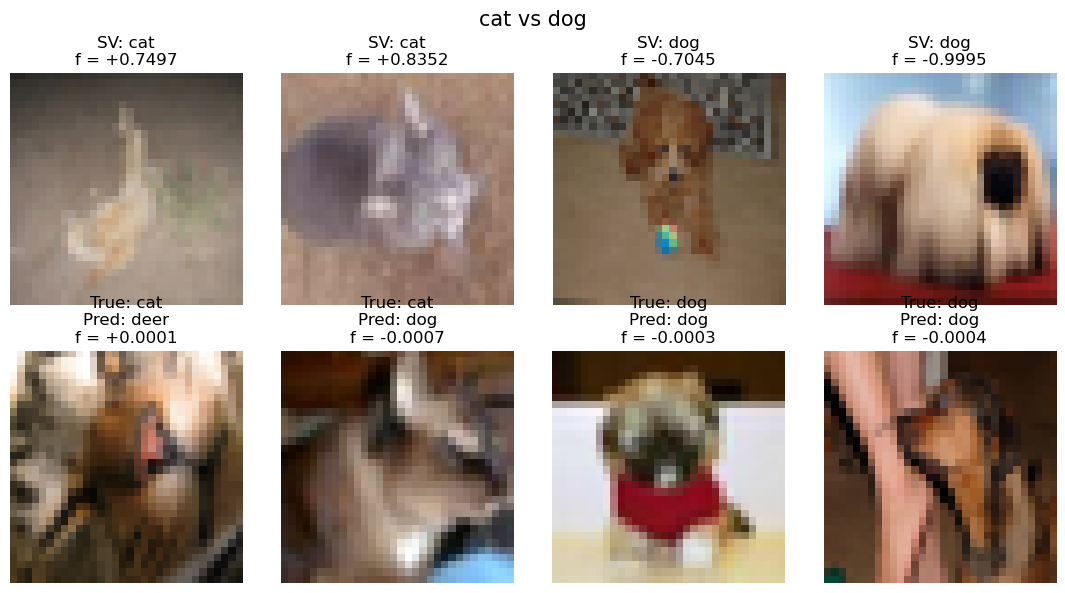

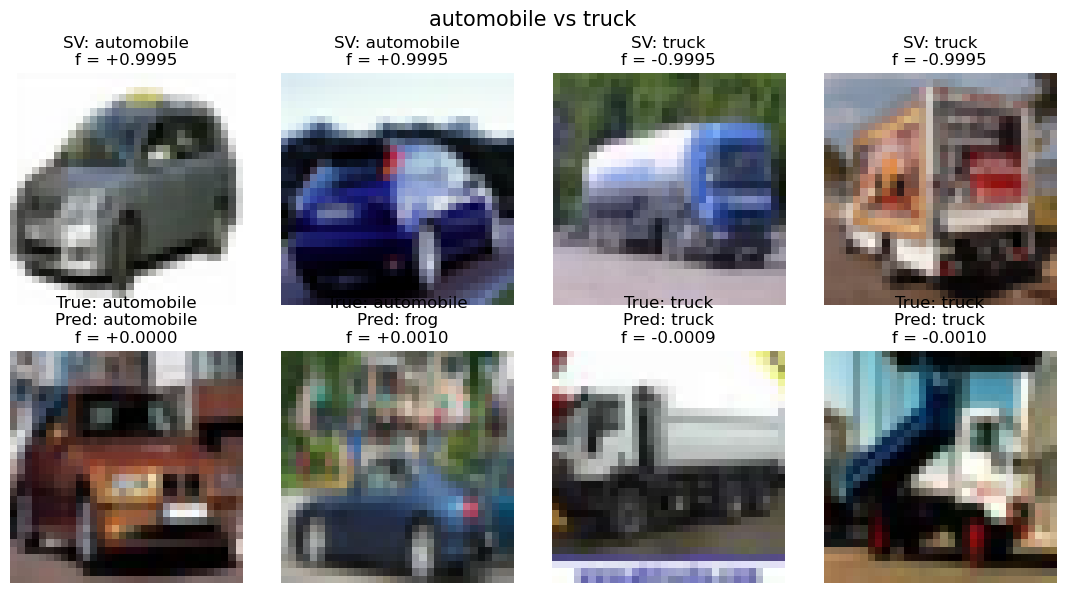

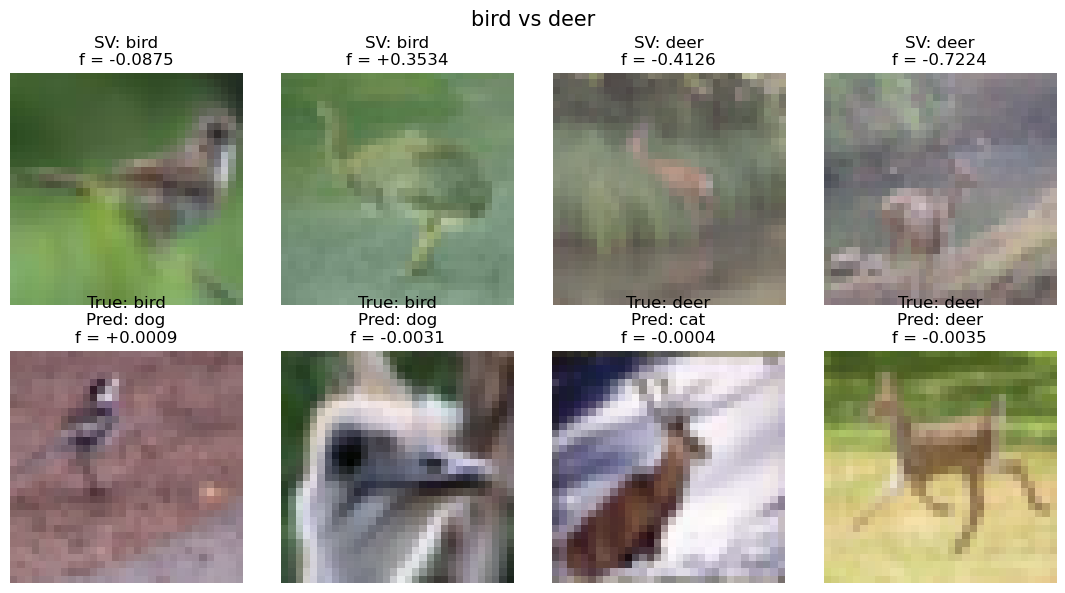

,Pair,Dataset,Image Index,True Class,Decision Score,Pairwise Decision,Multiclass Prediction
0,cat vs dog,Training support vector,43720,cat,0.7497,cat,NaN
1,cat vs dog,Training support vector,24036,cat,0.8352,cat,NaN
2,cat vs dog,Training support vector,48208,dog,-0.7045,dog,NaN
3,cat vs dog,Training support vector,3420,dog,-0.9995,dog,NaN
4,cat vs dog,Near-boundary test,8275,cat,0.0001,cat,deer
5,cat vs dog,Near-boundary test,6825,cat,-0.0007,dog,dog
6,cat vs dog,Near-boundary test,9661,dog,-0.0003,dog,dog
7,cat vs dog,Near-boundary test,2061,dog,-0.0004,dog,dog
8,automobile vs truck,Training support vector,23164,automobile,0.9995,automobile,NaN
9,automobile vs truck,Training support vector,7605,automobile,0.9995,automobile,NaN


In [159]:
boundary_examples = []
pair_geometry = []

for _, row in difficult_pairs.iterrows():

    a = int(row["a"])
    b = int(row["b"])

    pair_column = class_pairs.index((a, b))

    support_a, support_b = get_pair_support_vectors(a, b)

    # Select support vectors close to the pairwise boundary
    sv_a = support_a[
        np.argsort(
            np.abs(support_scores[support_a, pair_column])
        )[:2]
    ]

    sv_b = support_b[
        np.argsort(
            np.abs(support_scores[support_b, pair_column])
        )[:2]
    ]

    selected_support = np.concatenate([sv_a, sv_b])

    # Select the closest test examples from each true class
    test_a = np.flatnonzero(y_q4_test == a)
    test_b = np.flatnonzero(y_q4_test == b)

    near_a = test_a[
        np.argsort(
            np.abs(ovo_scores[test_a, pair_column])
        )[:2]
    ]

    near_b = test_b[
        np.argsort(
            np.abs(ovo_scores[test_b, pair_column])
        )[:2]
    ]

    selected_test = np.concatenate([near_a, near_b])

    fig, axes = plt.subplots(2, 4, figsize=(11, 6))

    for ax in axes.flat:
        ax.axis("off")

    # Training support vector images
    for col, position in enumerate(selected_support):

        subset_index = best_svm.support_[position]

        original_index = int(
            q4_original_indices[subset_index]
        )

        image, label = full_dataset[original_index]

        image = image * 0.5 + 0.5

        score = support_scores[position, pair_column]

        axes[0, col].imshow(
            image.permute(1, 2, 0).numpy()
        )

        axes[0, col].set_title(
            f"SV: {class_names[label]}\nf = {score:+.4f}"
        )

        boundary_examples.append({
            "Pair": f"{class_names[a]} vs {class_names[b]}",
            "Dataset": "Training support vector",
            "Image Index": original_index,
            "True Class": class_names[label],
            "Decision Score": score,
            "Pairwise Decision": class_names[a if score > 0 else b]
        })

    # Test examples closest to boundary
    for col, index in enumerate(selected_test):

        image, label = test_dataset[int(index)]

        image = image * 0.5 + 0.5

        predicted = svm_test_predictions[index]

        score = ovo_scores[index, pair_column]

        axes[1, col].imshow(
            image.permute(1, 2, 0).numpy()
        )

        axes[1, col].set_title(
            f"True: {class_names[label]}\n"
            f"Pred: {class_names[predicted]}\n"
            f"f = {score:+.4f}"
        )

        boundary_examples.append({
            "Pair": f"{class_names[a]} vs {class_names[b]}",
            "Dataset": "Near-boundary test",
            "Image Index": int(index),
            "True Class": class_names[label],
            "Decision Score": score,
            "Pairwise Decision": class_names[a if score > 0 else b],
            "Multiclass Prediction": class_names[predicted]
        })

    fig.suptitle(
        f"{class_names[a]} vs {class_names[b]}",
        fontsize=15
    )

    plt.tight_layout()

    plt.savefig(
        f"figures/q4b_pair_{a}_{b}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

boundary_examples_df = pd.DataFrame(boundary_examples)

display(boundary_examples_df.round(4))

boundary_examples_df.to_csv(
    "results/q4b_boundary_examples.csv",
    index=False
)

In [160]:
for _, row in difficult_pairs.iterrows():

    a = int(row["a"])
    b = int(row["b"])

    pair_column = class_pairs.index((a, b))

    scores = ovo_scores[:, pair_column]

    pair_test_rows = np.flatnonzero(
        np.isin(y_q4_test, [a, b])
    )

    ordered_rows = pair_test_rows[
        np.argsort(np.abs(scores[pair_test_rows]))
    ]

    number_near = len(ordered_rows) // 10

    near_rows = ordered_rows[:number_near]
    far_rows = ordered_rows[number_near:]

    near_error = np.mean(
        svm_test_predictions[near_rows] != y_q4_test[near_rows]
    ) * 100

    far_error = np.mean(
        svm_test_predictions[far_rows] != y_q4_test[far_rows]
    ) * 100

    support_a, support_b = get_pair_support_vectors(a, b)

    # Measure class separation in training feature space
    features_a = X_q4_train[y_q4_train == a]
    features_b = X_q4_train[y_q4_train == b]

    centroid_a = features_a.mean(axis=0)
    centroid_b = features_b.mean(axis=0)

    centroid_distance = np.linalg.norm(
        centroid_a - centroid_b
    )

    spread_a = np.mean(
        np.sum((features_a - centroid_a)**2, axis=1)
    )

    spread_b = np.mean(
        np.sum((features_b - centroid_b)**2, axis=1)
    )

    within_spread = np.sqrt(
        (spread_a + spread_b) / 2
    )

    separation_ratio = centroid_distance / (
        within_spread + 1e-12
    )

    pair_geometry.append({
        "Class Pair": f"{class_names[a]} vs {class_names[b]}",
        "Mutual Confusions": int(row["Total Confusions"]),
        "Pair Support Vectors": len(support_a) + len(support_b),
        "Near Boundary Error (%)": near_error,
        "Remaining Error (%)": far_error,
        "Centroid Distance": centroid_distance,
        "Centroid Separation Ratio": separation_ratio
    })

pair_geometry_df = pd.DataFrame(pair_geometry)

display(pair_geometry_df.round(4))

pair_geometry_df.to_csv(
    "results/q4b_geometry_analysis.csv",
    index=False
)

,Class Pair,Mutual Confusions,Pair Support Vectors,Near Boundary Error (%),Remaining Error (%),Centroid Distance,Centroid Separation Ratio
0,cat vs dog,421,965,76.5,63.8889,2.2601,0.0977
1,automobile vs truck,361,938,61.0,40.7778,4.2790,0.1682
2,bird vs deer,303,870,81.5,63.5000,2.5893,0.1344


## Q4(c) — Clustering on the same representation

In [161]:
test_ari = adjusted_rand_score(
    y_q4_test, test_cluster_ids
)

test_nmi = normalized_mutual_info_score(
    y_q4_test, test_cluster_ids
)

print("Selected K:", best_k)
print("Test ARI:", round(test_ari, 4))
print("Test NMI:", round(test_nmi, 4))
print("SVM Test Accuracy:", svm_test_accuracy)

clustering_final_df = pd.DataFrame([{
    "Representation": f"AE-{best_representation}",
    "Method": "KMeans",
    "Clusters": best_k,
    "Validation Silhouette": best_silhouette,
    "Test ARI": test_ari,
    "Test NMI": test_nmi
}])

display(clustering_final_df.round(4))

clustering_final_df.to_csv(
    "results/q4c_final_clustering_results.csv",
    index=False
)

Selected K: 5
Test ARI: 0.053
Test NMI: 0.0915
SVM Test Accuracy: 45.879999999999995


,Representation,Method,Clusters,Validation Silhouette,Test ARI,Test NMI
0,AE-512,KMeans,5,0.0016,0.053,0.0915


In [162]:
cluster_counts = pd.crosstab(
    y_q4_test,
    test_cluster_ids
).reindex(
    index=range(10),
    columns=range(best_k),
    fill_value=0
)

contingency_table = cluster_counts.copy()

contingency_table.index = class_names

contingency_table.columns = [
    f"Cluster {k}" for k in range(best_k)
]

display(contingency_table)

contingency_table.to_csv(
    "results/q4c_contingency_table.csv"
)

,Cluster 0,Cluster 1,Cluster 2,Cluster 3,Cluster 4
airplane,238,43,444,170,105
automobile,124,172,287,202,215
bird,104,162,166,63,505
cat,113,267,159,79,382
deer,35,202,93,76,594
dog,62,228,280,65,365
frog,86,269,61,29,555
horse,74,126,139,246,415
ship,39,58,497,340,66
truck,128,62,179,437,194


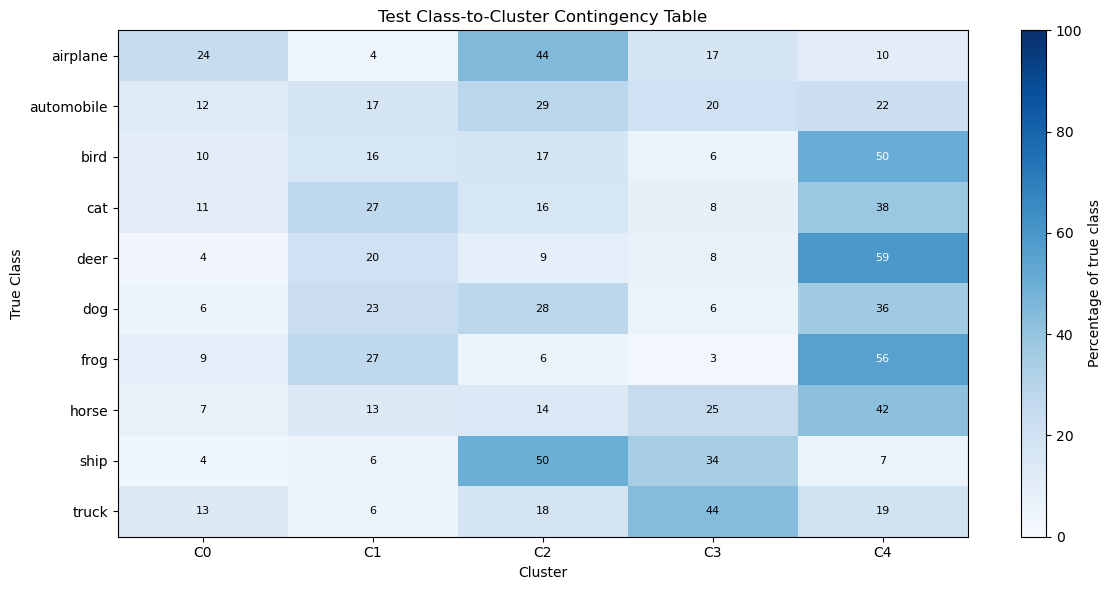

In [163]:
cluster_percent = cluster_counts.div(
    cluster_counts.sum(axis=1),
    axis=0
) * 100

plt.figure(figsize=(12, 6))

plt.imshow(
    cluster_percent,
    cmap="Blues",
    aspect="auto",
    vmin=0,
    vmax=100
)

plt.colorbar(label="Percentage of true class")

plt.xticks(
    range(best_k),
    [f"C{i}" for i in range(best_k)]
)

plt.yticks(range(10), class_names)

plt.xlabel("Cluster")
plt.ylabel("True Class")
plt.title("Test Class-to-Cluster Contingency Table")

for i in range(10):

    for j in range(best_k):

        value = cluster_percent.iloc[i, j]

        plt.text(
            j, i,
            f"{value:.0f}",
            ha="center",
            va="center",
            fontsize=8,
            color="white" if value > 50 else "black"
        )

plt.tight_layout()

plt.savefig(
    "figures/q4c_contingency_heatmap.png",
    dpi=300
)

plt.show()

In [164]:
disagreement_results = []

cluster_distributions = cluster_counts.div(
    cluster_counts.sum(axis=1),
    axis=0
).to_numpy()

for pair_column, (a, b) in enumerate(class_pairs):

    mask_a = y_q4_test == a
    mask_b = y_q4_test == b

    # Predictions from the selected SVM's actual pairwise classifier
    pair_predictions = np.where(
        ovo_scores[:, pair_column] > 0,
        a,
        b
    )

    acc_a = np.mean(pair_predictions[mask_a] == a)
    acc_b = np.mean(pair_predictions[mask_b] == b)

    svm_pair_accuracy = (acc_a + acc_b) / 2 * 100

    # Compare distributions of the two classes across clusters
    p_a = cluster_distributions[a]
    p_b = cluster_distributions[b]

    overlap = np.minimum(p_a, p_b).sum()

    cluster_pair_accuracy = (
        1 - overlap / 2
    ) * 100

    gap = svm_pair_accuracy - cluster_pair_accuracy

    shared_cluster = int(
        np.argmax(np.minimum(p_a, p_b))
    )

    disagreement_results.append({
        "a": a,
        "b": b,
        "Class A": class_names[a],
        "Class B": class_names[b],
        "SVM Pair Accuracy (%)": svm_pair_accuracy,
        "Cluster Overlap (%)": overlap * 100,
        "Cluster Binary Ceiling (%)": cluster_pair_accuracy,
        "Gap (pp)": gap,
        "SVM Multiclass Mutual Errors": (
            svm_cm[a, b] + svm_cm[b, a]
        ),
        "Most Shared Cluster": shared_cluster,
        "Class A in Shared Cluster": cluster_counts.iloc[a, shared_cluster],
        "Class B in Shared Cluster": cluster_counts.iloc[b, shared_cluster]
    })

disagreement_df = pd.DataFrame(disagreement_results)

disagreement_df["Absolute Gap"] = disagreement_df[
    "Gap (pp)"
].abs()

disagreement_df = disagreement_df.sort_values(
    "Absolute Gap", ascending=False
)

display(disagreement_df.head(5).round(4))

disagreement_df.to_csv(
    "results/q4c_classification_clustering_disagreement.csv",
    index=False
)

,a,b,Class A,Class B,SVM Pair Accuracy (%),Cluster Overlap (%),Cluster Binary Ceiling (%),Gap (pp),SVM Multiclass Mutual Errors,Most Shared Cluster,Class A in Shared Cluster,Class B in Shared Cluster,Absolute Gap
12,1,5,automobile,dog,89.75,79.4,60.30,29.45,67,2,287,280,29.45
14,1,7,automobile,horse,88.25,75.6,62.20,26.05,75,4,215,415,26.05
10,1,3,automobile,cat,88.20,73.8,63.10,25.10,77,4,215,382,25.10
9,1,2,automobile,bird,89.45,71.0,64.50,24.95,50,4,215,505,24.95
0,0,1,airplane,automobile,86.15,72.9,63.55,22.60,108,2,444,287,22.60


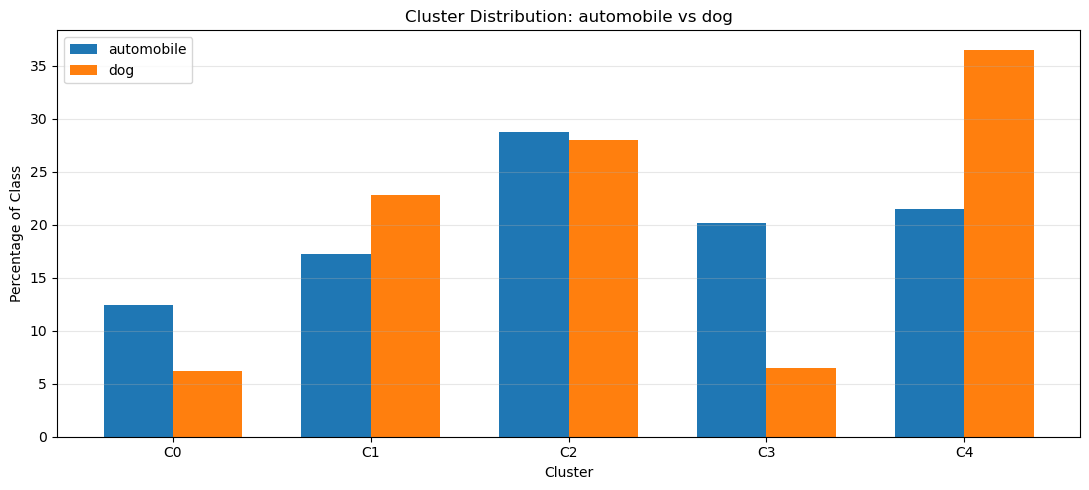

a                                        1
b                                        5
Class A                         automobile
Class B                                dog
SVM Pair Accuracy (%)                89.75
Cluster Overlap (%)                   79.4
Cluster Binary Ceiling (%)            60.3
Gap (pp)                             29.45
SVM Multiclass Mutual Errors            67
Most Shared Cluster                      2
Class A in Shared Cluster              287
Class B in Shared Cluster              280
Absolute Gap                         29.45
Name: 12, dtype: object

In [165]:
selected_disagreement = disagreement_df.iloc[0]

a = int(selected_disagreement["a"])
b = int(selected_disagreement["b"])

x = np.arange(best_k)
width = 0.35

plt.figure(figsize=(11, 5))

plt.bar(
    x - width / 2,
    cluster_distributions[a] * 100,
    width,
    label=class_names[a]
)

plt.bar(
    x + width / 2,
    cluster_distributions[b] * 100,
    width,
    label=class_names[b]
)

plt.xticks(
    x,
    [f"C{i}" for i in range(best_k)]
)

plt.xlabel("Cluster")
plt.ylabel("Percentage of Class")

plt.title(
    f"Cluster Distribution: "
    f"{class_names[a]} vs {class_names[b]}"
)

plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    "figures/q4c_class_disagreement.png",
    dpi=300
)

plt.show()

display(selected_disagreement)